# Contaminación del aire en la Zona Metropolitana del Valle de México
**Analítica Avanzada · Proyecto: Entregable de la Unidad I**

En este notebook documentamos el avance del proyecto. Está organizado con los siete puntos que pide la entrega y termina con lo que encontramos y lo que se puede hacer con ello.

**Abreviaturas que usamos:** ZMVM = Zona Metropolitana del Valle de México · O3 = ozono · PM2.5 = partículas finas (polvo y humo tan pequeños que llegan a los pulmones) · NO2 = dióxido de nitrógeno (sale sobre todo de los escapes) · SIMAT = Sistema de Monitoreo Atmosférico de la CDMX · "la norma" = el límite que marca la Norma Oficial Mexicana de salud.

## 1. Problemática a analizar

En la Zona Metropolitana del Valle de México viven más de 20 millones de personas y el aire rebasa con frecuencia los límites que protegen la salud, sobre todo por dos contaminantes:

- **Ozono (O3):** no sale directamente de los escapes; se forma en el aire cuando los gases de los autos y la industria reciben luz del sol. Irrita las vías respiratorias.
- **Partículas finas (PM2.5):** humo y polvo muy fino que entra hasta los pulmones.

Lo que nos llamó la atención es que **la contaminación cambia mucho de un día a otro aunque la ciudad funcione casi igual todos los días** (los mismos autos, las mismas fábricas). Eso sugiere que el clima del día (calor, viento, humedad) tiene mucho que ver.

**Preguntas del proyecto**

1. ¿Qué tanto se relaciona el clima y el calendario (mes, día de la semana, festivos) con la contaminación de cada día?
2. ¿Cuánta gente, y en especial niños y adultos mayores, vive en las zonas donde más veces se rebasa la norma?

**¿Para qué sirve?** Si los días malos se parecen entre sí (calor, poco viento, ayer también estuvo mal), se pueden anticipar y avisar a tiempo a quienes más lo necesitan.

## 2. Variables de entrada propuestas

Son los datos que conocemos de un día (o de una localidad) y que usaremos como información inicial para explicar la contaminación.

**Del día (dataset diario)**

| Grupo | Variable | Qué es | Por qué podría influir |
|---|---|---|---|
| Clima | `tmp_max` | Temperatura máxima del día (°C) | Con calor y sol se forma más ozono |
| Clima | `amplitud_termica` | Diferencia entre la temperatura máxima y la mínima (°C) | Días despejados y secos, en los que el aire se estanca |
| Clima | `rh_prom` | Humedad promedio (%) | Los días húmedos o lluviosos limpian el aire |
| Clima | `wsp_prom`, `wsp_madrugada` | Velocidad del viento en el día y de 1 a 8 de la mañana (m/s) | El viento se lleva la contaminación; sin viento se acumula |
| Clima | `viento_u`, `viento_v` | Dirección del viento (este-oeste y norte-sur) | Indica de dónde viene el aire |
| Calendario | `fin_semana`, `festivo` | 1 si es sábado/domingo o día festivo | Cambia el tráfico; en fiestas hay pirotecnia |
| Calendario | `dia_anio_sin`, `dia_anio_cos` | Época del año | La contaminación tiene temporadas |
| Calendario | `confinamiento` | 1 del 23 de marzo al 30 de junio de 2020 | Hubo muchos menos autos |
| Día anterior | `pm25_prom_ayer`, `o3_max1h_ayer` | Contaminación de ayer | Los días malos suelen venir seguidos |

**De la localidad (dataset por localidad)**

| Variable | Qué es |
|---|---|
| `POBTOT`, `POB0_14`, `POB65_MAS` | Población total, niños y adultos mayores (Censo 2020) |
| `PSINDER` | Personas sin servicio médico (sin derechohabiencia) |
| `GRAPROES` | Años de escuela promedio |
| `pm25_sat`, `no2_sat` | Contaminación estimada por satélite en 2020 |

## 3. Posibles variables objetivo

Son los resultados que queremos analizar y, más adelante, predecir.

| Variable | Qué mide | Tipo |
|---|---|---|
| `o3_max1h` | El valor más alto de ozono que se midió en el día (ppb). **Objetivo principal** | Número |
| `pm25_prom` | PM2.5 promedio del día (µg/m³) | Número |
| `excede_o3` | 1 si ese día el ozono rebasó la norma (90 ppb) | Sí / No |
| `excede_pm25` | 1 si ese día el PM2.5 rebasó la norma (41 µg/m³) | Sí / No |
| `o3_dias_sobre_nom` | Días al año que se rebasa la norma de ozono en la estación más cercana a cada localidad | Número (por localidad) |

Elegimos el ozono como objetivo principal porque, como se ve en el análisis, es el contaminante que más veces rebasa la norma.

## 4. Fuentes de datos exploradas

Estos son los lugares que revisamos para encontrar datos y lo que decidimos con cada uno.

| Fuente | Qué tiene | ¿Se usa? |
|---|---|---|
| **SIMAT**, Gobierno de la CDMX (aire.cdmx.gob.mx) | Contaminantes y clima medidos cada hora en las estaciones de monitoreo, 2015-2024 | **Sí.** Es la fuente principal: mediciones directas y día por día |
| **Censo 2020**, INEGI | Población de cada localidad de la CDMX y el Estado de México | **Sí.** Dice quién vive en cada lugar |
| **Satélite 2020**, grupo ACAG de la Universidad de Washington en San Luis | PM2.5 y NO2 estimados desde el espacio | **Sí**, pero antes revisamos si coincide con las estaciones |
| Promedios por localidad de la red de monitoreo (`cont_loc_mean.csv`) | Promedio de contaminación de 494 localidades de la CDMX | Solo como referencia |
| Egresos hospitalarios (SAEH, Secretaría de Salud) | Hospitalizaciones por municipio | **No.** Reflejaban dónde hay hospitales, no el efecto del aire |
| Inventario de emisiones 2020 (SEDEMA) | Emisiones de todo el año por tipo de fuente | **No.** Es un solo número por año; no sirve para ver cambios diarios |

## 5. Datos seleccionados

Nos quedamos con tres conjuntos de datos y los organizamos en **dos tablas**:

| Datos | Periodo | Para qué |
|---|---|---|
| SIMAT: 20 archivos por hora (10 de contaminantes y 10 de clima) | 2015-2024 | **Dataset diario**: un renglón por día. Es el dataset final de la entrega |
| Censo 2020 por localidad | 2020 | **Dataset por localidad**: quién vive dónde |
| Satélite de PM2.5 y NO2 | 2020 | Dataset por localidad: contaminación donde no hay estación |

**¿Por qué estos?** El SIMAT es la única fuente que cambia día con día, que es justo lo que queremos estudiar. El censo y el satélite se conservan porque las estaciones están casi todas en el centro de la ciudad y no dicen nada de quién respira ese aire. Las dos tablas se conectan por las **estaciones de monitoreo**: a cada localidad le asignamos su estación más cercana.

## 6. Construcción del dataset para exploración

### 6.1 Dataset diario

Los datos originales vienen **por hora y por estación** (casi 25 millones de registros). Para poder analizarlos los convertimos en **un renglón por día**. Los pasos son:

1. Descargar y leer los archivos del SIMAT.
2. Limpiar: quitar valores imposibles.
3. Resumir cada día en cada estación.
4. Juntar todas las estaciones en un solo renglón por día.
5. Agregar el calendario y la contaminación del día anterior.
6. Quitar las columnas que no son importantes para el análisis.
7. Guardar el dataset final.

**Paso 0. Preparar el entorno.** Las dos celdas siguientes solo ubican la carpeta del proyecto (funciona en Colab y en la computadora), cargan las librerías y definen los límites de la norma.

In [23]:
# Preparación del entorno: funciona en Google Colab y en local (VS Code / Jupyter)
import os, sys, io, gzip, subprocess
from pathlib import Path

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Carpeta del proyecto en Google Drive (la que contiene datos/rama)
PROYECTO_DRIVE = Path("/content/drive/MyDrive/Analítica avanzada/Entrega_1")

def es_proyecto(p):
    return (p / "datos").is_dir() and ((p / "datos" / "rama").is_dir() or (p / "datos" / "dataset_final_diario.csv").exists())

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not (PROYECTO_DRIVE / "datos" / "rama").is_dir():
        raise FileNotFoundError(f"No existe {PROYECTO_DRIVE / 'datos' / 'rama'}. Revisa el nombre exacto de las carpetas "
                                "(mayúsculas, acentos y espacios) y corrige PROYECTO_DRIVE.")
    os.chdir(PROYECTO_DRIVE)
elif not es_proyecto(Path.cwd()):
    for p in [Path.cwd().parent, Path.home() / "Documents/2027-1/Analitica_avanzada"]:
        if es_proyecto(p):
            os.chdir(p)
            break

print("Entorno:", "Colab" if EN_COLAB else "local", "| Carpeta del proyecto:", Path.cwd())

Entorno: local | Carpeta del proyecto: /Users/sayuriherreramoreno/Documents/2027-1/Analitica_avanzada


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from scipy import stats
from dateutil.easter import easter
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATOS = Path.cwd() / "datos"
RAMA = DATOS / "rama"            # archivos horarios originales (uno por año)
FIGURAS = Path.cwd() / "figuras_rama"   # figuras para el reporte
RAMA.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight", dpi=150)

AÑOS = list(range(2015, 2025))   # 10 años completos

# Límites de la normatividad mexicana (NOM-025-SSA1-2021 y NOM-020-SSA1-2021)
NOM_PM25_24H = 41    # µg/m³, promedio de 24 h (valor 2022-2023; en 2024-2025 bajó a 33)
NOM_O3_1H = 90       # ppb, promedio horario
OMS_PM25_24H = 15    # µg/m³, guía OMS 2021

COLOR = {"PM2.5": "#2a78d6", "O3": "#eb6834", "gris": "#7f7f7f"}

**Paso 1. Descargar los archivos.** Se bajan del sitio del SIMAT los archivos que falten (uno de contaminantes y uno de clima por cada año) y el catálogo de estaciones. Si ya están en la carpeta `datos/rama`, no se vuelven a descargar.

In [25]:
URL_BASE = "https://aire.cdmx.gob.mx/descargas/Opendata"
ARCHIVOS = {
    "cat_estacion.csv": f"{URL_BASE}/Bases_publicas/Data%20Set/catalogos/cat_estacion.csv",
    **{f"contaminantes_{a}.csv.gz": f"{URL_BASE}/anuales_horarios_gz/contaminantes_{a}.csv.gz" for a in AÑOS},
    # la meteorología solo se publica sin comprimir; se guarda comprimida para ahorrar espacio
    **{f"meteorologia_{a}.csv.gz": f"{URL_BASE}/anuales_horarios/meteorolog%C3%ADa_{a}.csv" for a in AÑOS},
}

import unicodedata

def clave(nombre):
    """Nombre sin acentos, en minúsculas y sin extensión (.csv, .gz, .zip), para encontrar el archivo
    aunque en Drive se llame p. ej. 'meteorología_2015.csv' en vez de 'meteorologia_2015.csv.gz'."""
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode().lower()
    for ext in (".gz", ".zip", ".csv"):
        n = n.removesuffix(ext)
    return n.strip()

def buscar(nombre):
    """Ruta real del archivo en RAMA (con cualquier variante de nombre/extensión) o None si no está."""
    exacto = RAMA / nombre
    if exacto.exists():
        return exacto
    indice = {clave(p.name): p for p in RAMA.iterdir() if p.is_file()}
    return indice.get(clave(nombre))

def descargar(nombre, url):
    if buscar(nombre) is not None:
        return "ya existe"
    destino = RAMA / nombre
    r = requests.get(url, timeout=600, headers={"User-Agent": "Mozilla/5.0"})
    r.raise_for_status()
    contenido = r.content
    if nombre.endswith(".gz") and not url.endswith(".gz"):
        contenido = gzip.compress(contenido)
    destino.write_bytes(contenido)
    return f"descargado ({len(contenido) / 1e6:.1f} MB)"

# Solo se descargan los archivos que falten (la primera vez en Colab tarda 2-5 minutos)
for nombre, url in ARCHIVOS.items():
    try:
        estado = descargar(nombre, url)
    except requests.RequestException as e:
        estado = f"FALLÓ ({e.__class__.__name__}). Súbelo a mano a {RAMA}"
    if estado != "ya existe":
        print(nombre, "→", estado)
# Diccionario nombre estándar → ruta real en tu Drive (lo usan las celdas siguientes)
RUTAS = {n: buscar(n) for n in ARCHIVOS}
faltan = [n for n, r in RUTAS.items() if r is None]
if faltan:
    print("Archivos que SÍ hay en", RAMA, ":", sorted(p.name for p in RAMA.iterdir()))
    raise FileNotFoundError(f"Faltan {len(faltan)} archivos en {RAMA}: {faltan}. Descárgalos de "
                            "https://aire.cdmx.gob.mx/default.php?opc='aKBhnmI='&opcion=Zg== (contaminantes) y "
                            "https://aire.cdmx.gob.mx/default.php?opc='aKBhnmI='&opcion=Zw== (meteorología)")

print(f"\nArchivos que se van a usar desde {RAMA}:")
print(pd.Series({n: f"{r.name} ({r.stat().st_size / 1e6:.1f} MB)" for n, r in RUTAS.items()}).to_string())


Archivos que se van a usar desde /Users/sayuriherreramoreno/Documents/2027-1/Analitica_avanzada/datos/rama:
cat_estacion.csv                      cat_estacion.csv (0.0 MB)
contaminantes_2015.csv.gz    contaminantes_2015.csv.gz (7.4 MB)
contaminantes_2016.csv.gz    contaminantes_2016.csv.gz (7.8 MB)
contaminantes_2017.csv.gz    contaminantes_2017.csv.gz (7.8 MB)
contaminantes_2018.csv.gz    contaminantes_2018.csv.gz (7.7 MB)
contaminantes_2019.csv.gz    contaminantes_2019.csv.gz (8.1 MB)
contaminantes_2020.csv.gz    contaminantes_2020.csv.gz (7.9 MB)
contaminantes_2021.csv.gz    contaminantes_2021.csv.gz (7.9 MB)
contaminantes_2022.csv.gz    contaminantes_2022.csv.gz (9.1 MB)
contaminantes_2023.csv.gz    contaminantes_2023.csv.gz (8.6 MB)
contaminantes_2024.csv.gz    contaminantes_2024.csv.gz (9.1 MB)
meteorologia_2015.csv.gz      meteorologia_2015.csv.gz (3.4 MB)
meteorologia_2016.csv.gz      meteorologia_2016.csv.gz (4.0 MB)
meteorologia_2017.csv.gz      meteorologia_2017.csv.gz (4.0

**Paso 2. Leer los archivos.** Hay un detalle: en 2022 el SIMAT cambió la forma de escribir la fecha y la hora. La función `leer_horario` deja los dos formatos iguales (fecha + hora del 1 al 24). Como ejemplo se muestra el año 2019.

In [26]:
import zipfile

def abrir(ruta):
    """Abre el archivo sin importar su formato real: zip (SIMAT desde 2022), gzip o CSV sin comprimir."""
    datos = Path(ruta).read_bytes()
    if datos[:2] == b"PK":
        z = zipfile.ZipFile(io.BytesIO(datos))
        return io.BytesIO(z.read(z.namelist()[0]))
    if datos[:2] == b"\x1f\x8b":
        return io.BytesIO(gzip.decompress(datos))
    return io.BytesIO(datos)

def leer_horario(ruta, año):
    """Lee un archivo anual del SIMAT y devuelve fecha + hora (1 a 24) de cada medición.

    - Las primeras 9 o 10 líneas son metadatos; se busca la línea que empieza con 'date'.
    - La hora marca el FINAL del promedio horario. Hasta 2021 viene como 'dd/mm/aaaa 01:00 ... 24:00';
      desde 2022 como 'aaaa-mm-dd 01:00:00 ... 23:00:00' y la hora 24 aparece como 00:00 del día siguiente.
      Restando una hora al final del intervalo, los dos formatos quedan iguales."""
    buf = abrir(ruta)
    cabecera = next(i for i, l in enumerate(buf.read(3000).decode("latin-1").splitlines())
                    if l.replace('"', "").startswith("date"))
    buf.seek(0)
    df = pd.read_csv(buf, skiprows=cabecera, encoding="latin-1",
                     usecols=["date", "id_station", "id_parameter", "value"],
                     dtype={"id_station": "category", "id_parameter": "category", "value": "float64"})
    txt = df["date"].astype(str)
    if txt.iloc[0][2] == "/":   # formato viejo dd/mm/aaaa HH:MM, con HH de 01 a 24
        fin = pd.to_datetime(txt.str[:10], format="%d/%m/%Y") + pd.to_timedelta(txt.str[11:13].astype(int), unit="h")
    else:                       # formato nuevo ISO
        fin = pd.to_datetime(txt, format="ISO8601", errors="coerce")
    df, fin = df[fin.notna()], fin[fin.notna()]          # descarta fechas ilegibles (si las hay)
    inicio = fin - pd.Timedelta(hours=1)
    df["fecha"] = inicio.dt.normalize()
    df["hora"] = (inicio.dt.hour + 1).astype("int8")
    return df.loc[df.fecha.dt.year == año].drop(columns="date")

muestra = leer_horario(RUTAS["contaminantes_2019.csv.gz"], 2019)
print("Ejemplo: contaminantes 2019 →", muestra.shape)
display(muestra.head())
display(muestra.groupby("id_parameter", observed=True)["value"]
              .agg(registros="size", con_valor="count", minimo="min", mediana="median", maximo="max")
              .assign(pct_faltante=lambda t: (1 - t.con_valor / t.registros) * 100).round(2))

Ejemplo: contaminantes 2019 → (2266536, 5)


,id_station,id_parameter,value,fecha,hora
0,ACO,CO,NaN,2019-01-01,1
1,ACO,NO,NaN,2019-01-01,1
2,ACO,NO2,NaN,2019-01-01,1
3,ACO,NOX,NaN,2019-01-01,1
4,ACO,O3,NaN,2019-01-01,1


,registros,con_valor,minimo,mediana,maximo,pct_faltante
id_parameter,,,,,,
CO,277488,200825,0.0,0.3,5.2,27.63
NO,268728,182922,0.0,3.0,456.0,31.93
NO2,295008,212201,0.0,19.0,109.0,28.07
NOX,268728,182922,0.0,25.0,509.0,31.93
O3,312528,246838,0.0,25.0,159.0,21.02
PM10,219000,146818,1.0,38.0,653.0,32.96
PM2.5,207408,127224,1.0,20.0,393.0,38.66
PMCO,131400,82989,1.0,17.0,294.0,36.84
SO2,286248,213932,0.0,1.0,219.0,25.26


**Paso 3. Limpiar.** Se marcan como dato faltante los valores imposibles (por ejemplo, una humedad mayor a 100%). También comparamos el promedio de cada año para ver si algo cambia de forma rara.

In [27]:
# Calidad de los datos horarios: faltantes por año y valores fuera de rango físico
RANGOS = {"PM2.5": (0, 1000), "PM10": (0, 1500), "O3": (0, 400), "NO2": (0, 500), "CO": (0, 50),
          "SO2": (0, 1000), "TMP": (-15, 45), "RH": (0, 100), "WSP": (0, 40), "WDR": (0, 360)}
PARAM_CONT = ["PM2.5", "PM10", "O3", "NO2", "CO", "SO2"]
PARAM_MET = ["TMP", "RH", "WSP", "WDR"]

def limpiar(df):
    """Quita parámetros que no se usan y marca como faltante lo que está fuera de rango."""
    df = df[df.id_parameter.isin(RANGOS)].copy()
    df["id_parameter"] = df.id_parameter.astype(str)
    lo = df.id_parameter.map(lambda p: RANGOS[p][0])
    hi = df.id_parameter.map(lambda p: RANGOS[p][1])
    fuera = df.value.notna() & ((df.value < lo) | (df.value > hi))
    df.loc[fuera, "value"] = np.nan
    return df, int(fuera.sum())

resumen_calidad = []
horario = {}
for a in AÑOS:
    c, fc = limpiar(leer_horario(RUTAS[f"contaminantes_{a}.csv.gz"], a))
    m, fm = limpiar(leer_horario(RUTAS[f"meteorologia_{a}.csv.gz"], a))
    horario[a] = pd.concat([c, m], ignore_index=True)
    for p, g in horario[a].groupby("id_parameter"):
        resumen_calidad.append({"año": a, "parametro": p, "registros": len(g),
                                "pct_faltante": g.value.isna().mean() * 100,
                                "estaciones": g.id_station.nunique()})
    print(a, "| registros:", f"{len(horario[a]):,}", "| fuera de rango:", fc + fm)

# Revisión de consistencia entre años: promedio anual de cada variable meteorológica
consistencia = pd.DataFrame({a: df[df.id_parameter.isin(["TMP", "RH", "WSP"])].groupby("id_parameter").value.mean()
                             for a, df in horario.items()}).round(2)
print("\nPromedio anual de las variables meteorológicas (todas las estaciones)")
display(consistencia)

# En 2024 la velocidad del viento se duplica en TODAS las estaciones y en todos los meses, sin cambio de unidad
# declarado en el archivo. Es un cambio de escala no documentado, no un cambio real del clima, así que el viento
# de 2024 (velocidad y dirección) se marca como faltante.
AÑOS_VIENTO_INVALIDO = [2024]
for a in AÑOS_VIENTO_INVALIDO:
    h = horario[a]
    h.loc[h.id_parameter.isin(["WSP", "WDR"]), "value"] = np.nan

calidad = pd.DataFrame(resumen_calidad)
tabla_faltantes = calidad.pivot(index="parametro", columns="año", values="pct_faltante").round(1)
tabla_estaciones = calidad.pivot(index="parametro", columns="año", values="estaciones")
print("\n% de horas sin dato por parámetro y año")
display(tabla_faltantes)
print("Número de estaciones que reportan cada parámetro")
display(tabla_estaciones)

2015 | registros: 2,122,848 | fuera de rango: 0
2016 | registros: 2,393,808 | fuera de rango: 0
2017 | registros: 2,400,240 | fuera de rango: 0
2018 | registros: 2,400,240 | fuera de rango: 0
2019 | registros: 2,538,096 | fuera de rango: 0
2020 | registros: 2,564,928 | fuera de rango: 5
2021 | registros: 2,565,264 | fuera de rango: 0
2022 | registros: 2,576,058 | fuera de rango: 5
2023 | registros: 2,557,808 | fuera de rango: 13
2024 | registros: 2,650,162 | fuera de rango: 0

Promedio anual de las variables meteorológicas (todas las estaciones)


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
id_parameter,,,,,,,,,,
RH,62.70,58.03,54.03,57.22,53.20,52.03,54.17,53.29,51.99,51.70
TMP,16.40,16.28,16.49,16.34,17.14,17.01,16.51,16.85,16.99,17.25
WSP,2.03,2.12,2.09,1.99,2.11,2.23,2.07,2.11,2.08,4.40



% de horas sin dato por parámetro y año


año,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
parametro,,,,,,,,,,
CO,20.9,19.7,18.0,18.8,27.6,31.2,31.3,32.0,28.7,36.5
NO2,26.8,25.6,29.0,28.0,28.1,34.3,34.9,36.6,35.1,42.1
O3,16.1,14.2,15.5,21.2,21.0,31.5,31.1,26.6,25.3,29.3
PM10,18.0,19.3,29.4,34.9,33.0,45.6,41.1,41.7,43.8,49.1
PM2.5,15.9,28.2,33.3,38.3,38.7,44.2,44.7,44.0,41.6,47.0
RH,8.3,7.2,6.3,16.1,16.8,18.2,18.5,14.5,21.0,37.4
SO2,20.1,19.0,14.7,18.8,25.3,31.4,34.6,31.6,33.5,36.8
TMP,9.1,7.9,9.5,16.5,13.2,14.4,21.3,21.1,23.9,49.0
WDR,8.6,9.7,10.1,11.8,7.6,13.7,21.7,15.8,18.5,41.9


Número de estaciones que reportan cada parámetro


año,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
parametro,,,,,,,,,,
CO,30,30,30,30,32,32,32,33,32,33
NO2,31,29,29,29,34,34,34,36,34,36
O3,35,34,34,34,36,36,36,36,34,36
PM10,24,24,25,25,25,25,26,28,26,28
PM2.5,20,21,21,21,24,24,24,24,22,24
RH,24,26,26,26,26,26,26,28,28,28
SO2,32,31,31,31,33,33,33,33,32,33
TMP,24,26,26,26,26,26,26,28,28,28
WDR,26,26,26,26,28,28,28,28,28,28


**Qué vimos en la limpieza**

- Los valores imposibles son muy pocos: 23 en diez años.
- **El viento de 2024 no es confiable:** su promedio sale aproximadamente al doble que en todos los años anteriores, en todas las estaciones, sin que el archivo avise de un cambio de unidad. Para no contaminar el análisis, el viento de 2024 se deja como dato faltante.

**Paso 4. Resumir cada día en cada estación.** De las 24 horas se calcula el promedio y el valor más alto. Un promedio solo se acepta si ese día hay al menos 18 horas con dato (75%); con menos, no sería representativo.

In [28]:
MIN_HORAS = 18   # criterio de suficiencia: un promedio diario es válido con al menos 75% de las horas

def diario_por_estacion(df):
    """Un renglón por estación y día con promedio, máximo y número de horas válidas de cada parámetro."""
    g = df.dropna(subset=["value"]).groupby(["fecha", "id_station", "id_parameter"], observed=True).value
    d = g.agg(prom="mean", maxh="max", horas="count").reset_index()
    d.loc[d.horas < MIN_HORAS, "prom"] = np.nan      # día incompleto: no se usa el promedio
    return d

def o3_8h_max(df):
    """Máximo diario del promedio móvil de 8 horas de ozono (como lo pide la NOM-020)."""
    o3 = df[df.id_parameter == "O3"].copy()
    o3["ts"] = o3.fecha + pd.to_timedelta(o3.hora.astype(int), unit="h")
    o3 = o3.sort_values(["id_station", "ts"])
    o3["m8"] = (o3.groupby("id_station", observed=True).value
                  .transform(lambda s: s.rolling(8, min_periods=6).mean()))
    return (o3.groupby(["fecha", "id_station"], observed=True).m8.max()
              .rename("o3_8h").reset_index())

def viento_vectorial(df):
    """Componentes u (este-oeste) y v (norte-sur) del viento, promediadas por día.
    La dirección es de dónde viene el viento (convención meteorológica)."""
    w = df[df.id_parameter.isin(["WSP", "WDR"])].dropna(subset=["value"])
    if w.empty:                      # año sin viento válido
        return pd.DataFrame({"fecha": pd.Series(dtype="datetime64[us]"), "id_station": pd.Series(dtype=str),
                             "u": pd.Series(dtype=float), "v": pd.Series(dtype=float)})
    w = (w.pivot_table(index=["fecha", "hora", "id_station"], columns="id_parameter", values="value", observed=True)
           .dropna())
    rad = np.deg2rad(w.WDR)
    w["u"] = -w.WSP * np.sin(rad)
    w["v"] = -w.WSP * np.cos(rad)
    return w.groupby(level=["fecha", "id_station"])[["u", "v"]].mean().reset_index()

partes, partes_o3, partes_viento, perfil = [], [], [], []
for a, df in horario.items():
    partes.append(diario_por_estacion(df))
    partes_o3.append(o3_8h_max(df))
    partes_viento.append(viento_vectorial(df))
    # perfil por hora del día (promedio de todas las estaciones), para el análisis del ciclo diario
    perfil.append(df[df.id_parameter.isin(PARAM_CONT + ["TMP", "WSP"])]
                    .groupby(["id_parameter", "hora"]).value.mean().rename(a))

est_dia = pd.concat(partes, ignore_index=True)
o3_8h = pd.concat(partes_o3, ignore_index=True)
viento = pd.concat(partes_viento, ignore_index=True)
perfil_horario = pd.concat(perfil, axis=1).mean(axis=1).unstack(0)

print("Renglones estación-día-parámetro:", f"{len(est_dia):,}")
print("Días con promedio válido (≥18 h):", f"{est_dia.prom.notna().mean() * 100:.1f}%")
display(est_dia.head())

Renglones estación-día-parámetro: 787,391
Días con promedio válido (≥18 h): 97.5%


,fecha,id_station,id_parameter,prom,maxh,horas
0,2015-01-01,ACO,CO,0.579167,1.2,24
1,2015-01-01,ACO,NO2,14.041667,29.0,24
2,2015-01-01,ACO,O3,21.208333,54.0,24
3,2015-01-01,ACO,PM10,75.708333,181.0,24
4,2015-01-01,ACO,RH,64.458333,96.0,24


**Paso 5. Un solo renglón por día.** Se juntan todas las estaciones: para el PM2.5 y el clima se toma el promedio entre estaciones (lo que respira una persona típica) y para el ozono el valor más alto de cualquier estación (así se declara una contingencia).

In [29]:
# Pasamos de estación-día a un solo renglón por día para toda la zona metropolitana
ancho = est_dia.pivot_table(index=["fecha", "id_station"], columns="id_parameter", values=["prom", "maxh"], observed=True)
ancho.columns = [f"{p}_{e}" for e, p in ancho.columns]
ancho = (ancho.reset_index()
              .merge(o3_8h, on=["fecha", "id_station"], how="left")
              .merge(viento, on=["fecha", "id_station"], how="left"))

agg = {
    # contaminantes: promedio entre estaciones (exposición típica) y máximo (peor estación)
    "pm25_prom": ("PM2.5_prom", "mean"), "pm25_max_est": ("PM2.5_prom", "max"), "n_est_pm25": ("PM2.5_prom", "count"),
    "pm10_prom": ("PM10_prom", "mean"),
    "no2_prom": ("NO2_prom", "mean"),
    "co_prom": ("CO_prom", "mean"),
    "so2_prom": ("SO2_prom", "mean"),
    "o3_max1h": ("O3_maxh", "max"), "o3_max1h_prom": ("O3_maxh", "mean"), "n_est_o3": ("O3_maxh", "count"),
    "o3_8h_max": ("o3_8h", "max"),
    # meteorología: promedio entre estaciones
    "tmp_prom": ("TMP_prom", "mean"), "tmp_max": ("TMP_maxh", "mean"),
    "rh_prom": ("RH_prom", "mean"),
    "wsp_prom": ("WSP_prom", "mean"), "wsp_max": ("WSP_maxh", "mean"),
    "viento_u": ("u", "mean"), "viento_v": ("v", "mean"),
}
dia = ancho.groupby("fecha").agg(**agg)

# Temperatura mínima: mínimo horario de cada estación, promediado entre estaciones
tmin = pd.concat([df[df.id_parameter == "TMP"].groupby(["fecha", "id_station"], observed=True).value.min()
                  for df in horario.values()])
dia["tmp_min"] = tmin.groupby(level="fecha").mean()
dia["amplitud_termica"] = dia.tmp_max - dia.tmp_min

# Viento en la madrugada (01-08 h): con poco viento los contaminantes se acumulan
madrugada = pd.concat([df[(df.id_parameter == "WSP") & df.hora.between(1, 8)].groupby("fecha").value.mean()
                       for df in horario.values()])
dia["wsp_madrugada"] = madrugada

# Calendario completo: aseguramos que no falte ningún día
dia = dia.reindex(pd.date_range(f"{AÑOS[0]}-01-01", f"{AÑOS[-1]}-12-31", freq="D")).rename_axis("fecha").reset_index()
print("Días:", len(dia))
display(dia.describe().T.round(2))

Días: 3653


,count,mean,min,25%,50%,75%,max,std
fecha,3653,2020-01-01 00:00:00,2015-01-01 00:00:00,2017-07-02 00:00:00,2020-01-01 00:00:00,2022-07-02 00:00:00,2024-12-31 00:00:00,NaN
pm25_prom,3653.0,20.918181,2.928541,14.985354,20.111604,25.78442,86.904903,8.697008
pm25_max_est,3653.0,28.852658,4.545455,20.565217,27.545455,35.142857,132.375,12.409113
n_est_pm25,3653.0,13.667123,3.0,13.0,14.0,15.0,19.0,2.006781
pm10_prom,3653.0,41.348155,8.573613,29.013029,39.716764,51.886016,115.797722,15.879036
no2_prom,3652.0,22.928849,7.6625,18.160575,22.26318,26.717184,72.193452,6.699452
co_prom,3652.0,0.477436,0.124735,0.3289,0.439449,0.590277,1.83183,0.198624
so2_prom,3653.0,3.554688,0.605993,1.495508,2.397582,4.25463,31.512112,3.361296
o3_max1h,3653.0,100.530523,22.0,83.0,102.0,119.0,210.0,27.669046
o3_max1h_prom,3653.0,74.618414,8.84,61.4,75.653846,88.5,143.217391,20.509124


**Paso 6. Calendario y día anterior.** Se agregan el mes, el día de la semana, los días festivos, la temporada, el periodo de confinamiento por COVID-19 y la contaminación de ayer. También se crean las columnas que dicen si ese día se rebasó la norma.

In [30]:
def festivos(año):
    """Días de descanso obligatorio (LFT) más jueves y viernes santos."""
    def lunes(mes, n):
        d = pd.Timestamp(año, mes, 1)
        d += pd.Timedelta(days=(7 - d.weekday()) % 7)
        return d + pd.Timedelta(weeks=n - 1)
    pascua = pd.Timestamp(easter(año))
    return {pd.Timestamp(año, 1, 1), lunes(2, 1), lunes(3, 3), pd.Timestamp(año, 5, 1), pd.Timestamp(año, 9, 16),
            lunes(11, 3), pd.Timestamp(año, 12, 25), pascua - pd.Timedelta(days=3), pascua - pd.Timedelta(days=2)}

FESTIVOS = set().union(*[festivos(a) for a in AÑOS])

def temporada(mes):
    if mes in (11, 12, 1, 2):
        return "Seca fría"
    if mes in (3, 4, 5):
        return "Seca caliente"
    return "Lluvias"

dia["año"] = dia.fecha.dt.year
dia["mes"] = dia.fecha.dt.month
dia["dia_semana"] = dia.fecha.dt.dayofweek          # 0 = lunes
dia["fin_semana"] = (dia.dia_semana >= 5).astype(int)
dia["festivo"] = dia.fecha.isin(FESTIVOS).astype(int)
dia["temporada"] = dia.mes.map(temporada)
# Confinamiento por COVID-19: Jornada Nacional de Sana Distancia y semáforo rojo en la ZMVM
dia["confinamiento"] = dia.fecha.between("2020-03-23", "2020-06-30").astype(int)
dia["dia_anio_sin"] = np.sin(2 * np.pi * dia.fecha.dt.dayofyear / 365.25)
dia["dia_anio_cos"] = np.cos(2 * np.pi * dia.fecha.dt.dayofyear / 365.25)

# Rezagos: la contaminación de ayer es información disponible hoy (persistencia)
dia = dia.sort_values("fecha")
for col in ["pm25_prom", "o3_max1h", "wsp_prom", "tmp_max"]:
    dia[f"{col}_ayer"] = dia[col].shift(1)

# Variables objetivo binarias (días que rebasan la norma)
dia["excede_pm25"] = np.where(dia.pm25_max_est.notna(), (dia.pm25_max_est > NOM_PM25_24H).astype(float), np.nan)
dia["excede_o3"] = np.where(dia.o3_max1h.notna(), (dia.o3_max1h > NOM_O3_1H).astype(float), np.nan)

final = dia.copy()
print("Dataset final:", final.shape)
display(final.head())

Dataset final: (3653, 37)


,fecha,pm25_prom,pm25_max_est,n_est_pm25,pm10_prom,no2_prom,co_prom,so2_prom,o3_max1h,o3_max1h_prom,n_est_o3,o3_8h_max,tmp_prom,tmp_max,rh_prom,wsp_prom,wsp_max,viento_u,viento_v,tmp_min,amplitud_termica,wsp_madrugada,año,mes,dia_semana,fin_semana,festivo,temporada,confinamiento,dia_anio_sin,dia_anio_cos,pm25_prom_ayer,o3_max1h_ayer,wsp_prom_ayer,tmp_max_ayer,excede_pm25,excede_o3
0,2015-01-01,78.721165,96.583333,12,104.051185,24.207827,1.051096,11.584310,108.0,70.714286,28,70.500000,13.385714,20.735714,60.565476,1.933333,3.976471,-0.512328,0.856291,6.985714,13.750000,1.297794,2015,1,3,0,1,Seca fría,0,0.017202,0.999852,NaN,NaN,NaN,NaN,1.0,1.0
1,2015-01-02,15.462064,22.090909,12,36.449096,21.496300,0.807511,1.893310,48.0,40.250000,28,41.285714,13.567262,20.135714,52.452381,2.559804,5.564706,-0.177372,1.771245,7.142857,12.992857,1.275000,2015,1,4,0,0,Seca fría,0,0.034398,0.999408,78.721165,108.0,1.933333,20.735714,0.0,0.0
2,2015-01-03,12.986164,18.083333,12,29.601542,19.396739,0.641649,1.436788,43.0,35.678571,28,34.250000,13.907711,19.992857,55.683171,2.139283,4.670588,0.070637,1.062342,8.828571,11.164286,1.512500,2015,1,5,1,0,Seca fría,0,0.051584,0.998669,15.462064,48.0,2.559804,20.135714,0.0,0.0
3,2015-01-04,16.827126,20.791667,13,40.103561,19.542104,0.725397,1.809118,68.0,53.285714,28,48.375000,12.536012,19.171429,62.776786,2.592647,5.611765,0.409113,-1.574728,7.985714,11.185714,1.178676,2015,1,6,1,0,Seca fría,0,0.068755,0.997634,12.986164,43.0,2.139283,19.992857,0.0,0.0
4,2015-01-05,12.623773,17.791667,13,32.180793,20.952852,0.530754,8.267253,36.0,25.464286,28,30.875000,8.797727,12.342857,71.969697,2.916667,4.429412,1.248521,-2.259574,6.342857,6.000000,3.117391,2015,1,0,0,0,Seca fría,0,0.085906,0.996303,16.827126,68.0,2.592647,19.171429,0.0,0.0


**Paso 7. Quitar las columnas que no son importantes.** Hasta aquí la tabla tiene 37 columnas, pero no todas sirven para el análisis: algunas repiten la misma información de otra forma, otras solo se usaron para armar la tabla y otras no las ocupamos. Nos quedamos solo con las variables objetivo y las variables de entrada de los puntos 2 y 3.

In [31]:
QUITAR = {
    "pm25_max_est": "Repite al PM2.5; solo se usó para saber si se rebasó la norma (eso ya está en excede_pm25)",
    "o3_max1h_prom": "Otra forma de medir el ozono; nos quedamos con o3_max1h",
    "o3_8h_max": "Otra forma de medir el ozono; nos quedamos con o3_max1h",
    "pm10_prom": "Contaminante que no es objetivo del proyecto",
    "so2_prom": "Contaminante que no es objetivo del proyecto",
    "n_est_pm25": "Solo era un control de cuántas estaciones tenían dato",
    "n_est_o3": "Solo era un control de cuántas estaciones tenían dato",
    "tmp_prom": "Repite información de la temperatura máxima y mínima",
    "wsp_max": "Repite información del viento promedio",
    "temporada": "Repite información del mes",
    "wsp_prom_ayer": "No se usa en el análisis",
    "tmp_max_ayer": "No se usa en el análisis",
}
print("Columnas antes:", final.shape[1])
final = final.drop(columns=list(QUITAR))
print("Columnas después:", final.shape[1])
display(pd.Series(QUITAR, name="por qué se quita").rename_axis("columna eliminada").to_frame())

Columnas antes: 37
Columnas después: 25


,por qué se quita
columna eliminada,
pm25_max_est,Repite al PM2.5; solo se usó para saber si se ...
o3_max1h_prom,Otra forma de medir el ozono; nos quedamos con...
o3_8h_max,Otra forma de medir el ozono; nos quedamos con...
pm10_prom,Contaminante que no es objetivo del proyecto
so2_prom,Contaminante que no es objetivo del proyecto
n_est_pm25,Solo era un control de cuántas estaciones tení...
n_est_o3,Solo era un control de cuántas estaciones tení...
tmp_prom,Repite información de la temperatura máxima y ...
wsp_max,Repite información del viento promedio


**Paso 8. Guardar.** Se guarda el dataset final, un diccionario con la descripción de cada columna y el archivo con las primeras 100 filas

In [32]:
DICCIONARIO = {
    "fecha": "Día (2015-01-01 a 2024-12-31)",
    "pm25_prom": "OBJETIVO. PM2.5 promedio de 24 h, promedio de las estaciones (µg/m³)",
    "pm25_max_est": "PM2.5 promedio de 24 h en la estación más alta del día (µg/m³)",
    "n_est_pm25": "Estaciones con PM2.5 válido ese día",
    "pm10_prom": "PM10 promedio de 24 h, promedio de estaciones (µg/m³)",
    "no2_prom": "NO2 promedio de 24 h (ppb)",
    "co_prom": "CO promedio de 24 h (ppm)",
    "so2_prom": "SO2 promedio de 24 h (ppb)",
    "o3_max1h": "OBJETIVO PRINCIPAL. Máximo horario de ozono en cualquier estación (ppb)",
    "o3_max1h_prom": "Máximo horario de ozono, promedio de estaciones (ppb)",
    "n_est_o3": "Estaciones con ozono ese día",
    "o3_8h_max": "Máximo del promedio móvil de 8 h de ozono (ppb)",
    "tmp_prom": "Temperatura promedio (°C)",
    "tmp_max": "Temperatura máxima (°C), promedio de estaciones",
    "tmp_min": "Temperatura mínima (°C), promedio de estaciones",
    "amplitud_termica": "tmp_max − tmp_min (°C); valores altos se asocian a inversiones térmicas",
    "rh_prom": "Humedad relativa promedio (%)",
    "wsp_prom": "Velocidad del viento promedio (m/s)",
    "wsp_max": "Velocidad máxima horaria del viento (m/s), promedio de estaciones",
    "wsp_madrugada": "Velocidad del viento de 01 a 08 h (m/s)",
    "viento_u": "Componente este-oeste del viento (m/s, positivo = hacia el este)",
    "viento_v": "Componente norte-sur del viento (m/s, positivo = hacia el norte)",
    "año": "Año", "mes": "Mes", "dia_semana": "Día de la semana (0 = lunes)",
    "fin_semana": "1 si es sábado o domingo", "festivo": "1 si es día festivo oficial o jueves/viernes santo",
    "temporada": "Seca fría (nov-feb), seca caliente (mar-may), lluvias (jun-oct)",
    "confinamiento": "1 entre el 23 de marzo y el 30 de junio de 2020",
    "dia_anio_sin": "Seno del día del año (estacionalidad)", "dia_anio_cos": "Coseno del día del año",
    "pm25_prom_ayer": "PM2.5 del día anterior", "o3_max1h_ayer": "Ozono máximo del día anterior",
    "wsp_prom_ayer": "Viento promedio del día anterior", "tmp_max_ayer": "Temperatura máxima del día anterior",
    "excede_pm25": f"OBJETIVO BINARIO. 1 si alguna estación rebasó {NOM_PM25_24H} µg/m³ de PM2.5 (24 h)",
    "excede_o3": f"OBJETIVO BINARIO. 1 si alguna estación rebasó {NOM_O3_1H} ppb de ozono (1 h)",
}
DICCIONARIO = {c: d for c, d in DICCIONARIO.items() if c in final.columns}   # solo las columnas que se conservan
faltan_desc = set(final.columns) - set(DICCIONARIO)
assert not faltan_desc, faltan_desc
final = final[list(DICCIONARIO)]
final.to_csv(DATOS / "dataset_final_diario.csv", index=False)
est_dia.to_csv(DATOS / "rama_diario_estacion.csv.gz", index=False)
perfil_horario.to_csv(DATOS / "rama_perfil_horario.csv")
pd.Series(DICCIONARIO, name="descripcion").rename_axis("variable").to_csv(DATOS / "diccionario_dataset_diario.csv")
# Entregable: primeras 100 filas del dataset final
final.head(100).to_csv("dataset_final_100_filas.csv", index=False)
print("Guardado: datos/dataset_final_diario.csv", final.shape)
print("Guardado: dataset_final_100_filas.csv", final.head(100).shape)

Guardado: datos/dataset_final_diario.csv (3653, 25)
Guardado: dataset_final_100_filas.csv (100, 25)


**Resultado:** el dataset final tiene **3,653 días** (del 1 de enero de 2015 al 31 de diciembre de 2024) y **25 columnas**: la fecha, 4 variables objetivo y 20 columnas de entrada o de apoyo (clima, calendario, día anterior y los gases NO2 y CO).

### 6.2 Dataset por localidad

Sirve para la segunda pregunta: quién vive donde más se rebasa la norma. Se arma en tres pasos:

1. Cargar el censo, el satélite y el catálogo de estaciones.
2. Calcular, para cada estación, cuántos días al año rebasa la norma.
3. A cada localidad asignarle su estación más cercana. Solo se toma en cuenta si está a **5 km o menos**; más lejos ya no la representa.

In [33]:
# Datos del EDA anterior: Censo 2020 por localidad, promedios de la RAMA por localidad y satélite 2020
import re
import xarray as xr
import geopandas as gpd

DT = {"ENTIDAD": str, "MUN": str, "LOC": str}
inegi = pd.read_csv(DATOS / "inegi_loc.csv", dtype=DT, low_memory=False)
cont_loc = pd.read_csv(DATOS / "cont_loc_mean.csv", dtype=DT)
pm25_sat = xr.open_dataset(DATOS / "pm25_satelite_2020.nc")["pm25_sat"]
no2_sat = xr.open_dataset(DATOS / "no2_satelite_2020.nc")["no2_sat"]
municipios = gpd.read_file(DATOS / "municipios_cdmx_edomex.gpkg").to_crs(4326)

def dms_a_decimal(valor):
    """Convierte coordenadas del INEGI como 99°11'03.698\" W a grados decimales (función del EDA anterior)."""
    m = re.match(r"\s*(\d+)°(\d+)'([\d.]+)\"\s*([NSEW])", str(valor))
    if not m:
        return np.nan
    g = float(m.group(1)) + float(m.group(2)) / 60 + float(m.group(3)) / 3600
    return -g if m.group(4) in ("W", "S") else g

inegi["lon"] = inegi.LONGITUD.map(dms_a_decimal)
inegi["lat"] = inegi.LATITUD.map(dms_a_decimal)
for d in (inegi, cont_loc):
    d["ENTIDAD"] = d.ENTIDAD.str.zfill(2)
    d["MUN"] = d.MUN.str.zfill(3)
    d["LOC"] = d.LOC.str.zfill(4)
    d["cve_loc"] = d.ENTIDAD + d.MUN + d.LOC

estaciones = pd.read_csv(RUTAS["cat_estacion.csv"], skiprows=1, encoding="latin-1")
print("Localidades del censo:", inegi.shape, "| con promedio RAMA (EDA anterior):", len(cont_loc),
      "| estaciones en el catálogo:", len(estaciones))
print("Población total:", f"{inegi.POBTOT.sum():,}")

Localidades del censo: (5085, 235) | con promedio RAMA (EDA anterior): 494 | estaciones en el catálogo: 69
Población total: 26,194,902


In [34]:
# Resumen por estación a partir de los datos diarios nuevos (2015-2024)
def resumen_estacion(param, umbral, columna):
    d = est_dia[est_dia.id_parameter == param].copy()
    d["año"] = d.fecha.dt.year
    valor = d[columna]
    d["valido"] = valor.notna()
    d["sobre"] = valor > umbral
    r = d.groupby("id_station", observed=True).agg(dias_validos=("valido", "sum"), dias_sobre=("sobre", "sum"))
    r["dias_sobre_por_año"] = r.dias_sobre / r.dias_validos * 365      # normaliza por los días con dato
    r["prom_2020"] = d[d.año == 2020].groupby("id_station", observed=True)["prom"].mean()
    r["prom_2015_2024"] = d.groupby("id_station", observed=True)["prom"].mean()
    return r[r.dias_validos >= 365]                                       # al menos un año de datos

res_pm25 = resumen_estacion("PM2.5", NOM_PM25_24H, "prom").add_prefix("pm25_")
res_o3 = resumen_estacion("O3", NOM_O3_1H, "maxh").add_prefix("o3_")
res_no2 = resumen_estacion("NO2", 9999, "prom")[["prom_2020", "prom_2015_2024"]].add_prefix("no2_")
est = (estaciones.drop(columns="id_station").rename(columns={"cve_estac": "id_station"})[["id_station", "nom_estac", "longitud", "latitud", "alt"]]
       .merge(res_pm25, left_on="id_station", right_index=True, how="left")
       .merge(res_o3, left_on="id_station", right_index=True, how="left")
       .merge(res_no2, left_on="id_station", right_index=True, how="left"))
est = est[est[["pm25_dias_validos", "o3_dias_validos", "no2_prom_2020"]].notna().any(axis=1)].reset_index(drop=True)

# Valor del satélite en la celda de cada estación
X = xr.DataArray(est.longitud.values, dims="p")
Y = xr.DataArray(est.latitud.values, dims="p")
est["pm25_sat"] = pm25_sat.sel(lon=X, lat=Y, method="nearest").values
est["no2_sat"] = no2_sat.sel(lon=X, lat=Y, method="nearest").values
print("Estaciones con datos 2015-2024:", len(est))
display(est[["id_station", "nom_estac", "pm25_prom_2020", "pm25_sat", "no2_prom_2020", "no2_sat",
             "pm25_dias_sobre_por_año", "o3_dias_sobre_por_año"]].round(1).sort_values("o3_dias_sobre_por_año", ascending=False))

Estaciones con datos 2015-2024: 36


,id_station,nom_estac,pm25_prom_2020,pm25_sat,no2_prom_2020,no2_sat,pm25_dias_sobre_por_año,o3_dias_sobre_por_año
23,PED,Pedregal,17.6,20.299999,16.4,16.400000,4.9,163.6
6,CCA,Centro de Ciencias de la Atmósfera,17.5,20.799999,17.1,16.100000,6.5,161.8
8,COY,Coyoacán,NaN,21.100000,NaN,18.100000,27.2,159.5
2,AJM,Ajusco Medio,NaN,22.600000,12.4,14.100000,6.5,156.5
30,UAX,UAM Xochimilco,18.3,22.200001,17.6,17.100000,7.8,150.7
4,BJU,Benito Juárez,18.1,22.000000,19.8,18.799999,12.6,144.6
25,SFE,Santa fe,15.9,25.000000,16.4,15.000000,3.6,141.4
13,HGM,Hospital General de México,NaN,22.500000,21.1,19.799999,22.3,138.6
15,IZT,Iztacalco,NaN,23.100000,23.6,20.500000,NaN,129.5
19,MGH,Mguel Hidalgo,NaN,21.000000,23.1,19.000000,16.5,125.7


In [35]:
# Dataset por localidad: censo + satélite + promedios RAMA del EDA anterior + estación RAMA más cercana
cols_censo = ["cve_loc", "ENTIDAD", "NOM_ENT", "MUN", "NOM_MUN", "NOM_LOC", "lon", "lat", "ALTITUD",
              "POBTOT", "POB0_14", "POB65_MAS", "PCON_DISC", "PSINDER", "GRAPROES", "VPH_AUTOM", "TVIVPARHAB"]
loc = inegi[cols_censo].copy()
X = xr.DataArray(loc.lon.values, dims="p")
Y = xr.DataArray(loc.lat.values, dims="p")
loc["pm25_sat"] = pm25_sat.sel(lon=X, lat=Y, method="nearest").values
loc["no2_sat"] = no2_sat.sel(lon=X, lat=Y, method="nearest").values
loc = loc.merge(cont_loc[["cve_loc", "pm25_mean", "no2_mean", "o3_mean"]]
                .rename(columns={"pm25_mean": "pm25_rama_loc", "no2_mean": "no2_rama_loc", "o3_mean": "o3_rama_loc"}),
                on="cve_loc", how="left")

def distancia_km(lon1, lat1, lon2, lat2):
    """Distancia en km sobre la esfera (haversine)."""
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def estacion_cercana(param):
    """Para cada localidad, la estación más cercana que mide ese contaminante y su distancia."""
    e = est[est[f"{param}_dias_validos"].notna()].reset_index(drop=True)
    D = distancia_km(loc.lon.values[:, None], loc.lat.values[:, None], e.longitud.values[None, :], e.latitud.values[None, :])
    i = D.argmin(axis=1)
    return e.id_station.values[i], D[np.arange(len(loc)), i], e[f"{param}_dias_sobre_por_año"].values[i]

for param in ["pm25", "o3"]:
    loc[f"est_{param}"], loc[f"dist_est_{param}_km"], loc[f"{param}_dias_sobre_nom"] = estacion_cercana(param)

RADIO_KM = 5   # radio en el que la estación se considera representativa de la localidad
for param in ["pm25", "o3"]:
    loc.loc[loc[f"dist_est_{param}_km"] > RADIO_KM, f"{param}_dias_sobre_nom"] = np.nan

loc["pct_0a14"] = loc.POB0_14 / loc.POBTOT * 100
loc["pct_65mas"] = loc.POB65_MAS / loc.POBTOT * 100
loc["pct_sin_derechohab"] = loc.PSINDER / loc.POBTOT * 100
loc["pct_viv_auto"] = loc.VPH_AUTOM / loc.TVIVPARHAB * 100
loc = loc.replace([np.inf, -np.inf], np.nan)

loc.to_csv(DATOS / "dataset_localidades.csv", index=False)
est.to_csv(DATOS / "resumen_estaciones.csv", index=False)
print("Dataset por localidad:", loc.shape)
print(f"Localidades a ≤{RADIO_KM} km de una estación de ozono:", int(loc.o3_dias_sobre_nom.notna().sum()),
      f"({loc.loc[loc.o3_dias_sobre_nom.notna(), 'POBTOT'].sum() / loc.POBTOT.sum() * 100:.0f}% de la población)")
print(f"Localidades a ≤{RADIO_KM} km de una estación de PM2.5:", int(loc.pm25_dias_sobre_nom.notna().sum()),
      f"({loc.loc[loc.pm25_dias_sobre_nom.notna(), 'POBTOT'].sum() / loc.POBTOT.sum() * 100:.0f}% de la población)")
display(loc.describe().T.round(2))

Dataset por localidad: (5085, 32)
Localidades a ≤5 km de una estación de ozono: 438 (61% de la población)
Localidades a ≤5 km de una estación de PM2.5: 243 (43% de la población)


,count,mean,std,min,25%,50%,75%,max
lon,5085.0,-99.60,0.48,-100.58,-100.00,-99.63,-99.16,-98.62
lat,5085.0,19.34,0.38,18.37,19.07,19.32,19.65,20.27
ALTITUD,5085.0,2301.78,557.70,345.00,2237.00,2466.00,2651.00,3498.00
POBTOT,5085.0,5151.41,53280.53,3.00,111.00,384.00,1186.00,1835486.00
POB0_14,5085.0,1135.57,10734.65,0.00,32.00,116.00,356.00,366835.00
POB65_MAS,5085.0,448.40,5397.08,0.00,7.00,25.00,70.00,174312.00
PCON_DISC,5085.0,245.82,2814.41,0.00,4.00,16.00,51.00,104424.00
PSINDER,5085.0,1607.58,16883.86,0.00,20.00,103.00,397.00,594796.00
GRAPROES,5085.0,8.12,1.78,0.50,6.89,8.11,9.20,17.60
VPH_AUTOM,5085.0,635.70,6773.09,0.00,9.00,32.00,108.00,197085.00


**Resultado:** 5,085 localidades y 32 columnas. Las estaciones de ozono cubren (a 5 km o menos) a 438 localidades donde vive el **61% de la población**; el resto queda sin una estación cercana.

En la tabla de estaciones se ve que las que más días rebasan la norma de ozono están en el **sur y poniente** de la ciudad (Pedregal, Ciudad Universitaria, Coyoacán, Ajusco): más de 150 días al año.

## 7. Análisis estadístico básico del dataset final

Esta sección es el **análisis exploratorio de datos (EDA)**: revisar los datos con tablas y gráficas para conocerlos antes de construir cualquier modelo. Seguimos los pasos habituales de un EDA, y en cada uno decimos **qué buscamos** y **qué obtuvimos**.

### 7.1 Conocer el dataset

**Qué buscamos:** saber el tamaño de la tabla, qué representa cada renglón y de qué tipo es cada columna.

In [50]:
print("Filas (días):", final.shape[0], "| Columnas:", final.shape[1])
print("Periodo:", final.fecha.min().date(), "a", final.fecha.max().date())
print("\nTipo de dato de cada columna")
display(final.dtypes.astype(str).rename("tipo de dato").to_frame().T)
print("Primeras filas")
display(final.head())

Filas (días): 3653 | Columnas: 25
Periodo: 2015-01-01 a 2024-12-31

Tipo de dato de cada columna


,fecha,pm25_prom,no2_prom,co_prom,o3_max1h,tmp_max,tmp_min,amplitud_termica,rh_prom,wsp_prom,wsp_madrugada,viento_u,viento_v,año,mes,dia_semana,fin_semana,festivo,confinamiento,dia_anio_sin,dia_anio_cos,pm25_prom_ayer,o3_max1h_ayer,excede_pm25,excede_o3
tipo de dato,datetime64[ns],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int32,int32,int32,int64,int64,int64,float64,float64,float64,float64,float64,float64


Primeras filas


,fecha,pm25_prom,no2_prom,co_prom,o3_max1h,tmp_max,tmp_min,amplitud_termica,rh_prom,wsp_prom,wsp_madrugada,viento_u,viento_v,año,mes,dia_semana,fin_semana,festivo,confinamiento,dia_anio_sin,dia_anio_cos,pm25_prom_ayer,o3_max1h_ayer,excede_pm25,excede_o3
0,2015-01-01,78.721165,24.207827,1.051096,108.0,20.735714,6.985714,13.750000,60.565476,1.933333,1.297794,-0.512328,0.856291,2015,1,3,0,1,0,0.017202,0.999852,NaN,NaN,1.0,1.0
1,2015-01-02,15.462064,21.496300,0.807511,48.0,20.135714,7.142857,12.992857,52.452381,2.559804,1.275000,-0.177372,1.771245,2015,1,4,0,0,0,0.034398,0.999408,78.721165,108.0,0.0,0.0
2,2015-01-03,12.986164,19.396739,0.641649,43.0,19.992857,8.828571,11.164286,55.683171,2.139283,1.512500,0.070637,1.062342,2015,1,5,1,0,0,0.051584,0.998669,15.462064,48.0,0.0,0.0
3,2015-01-04,16.827126,19.542104,0.725397,68.0,19.171429,7.985714,11.185714,62.776786,2.592647,1.178676,0.409113,-1.574728,2015,1,6,1,0,0,0.068755,0.997634,12.986164,43.0,0.0,0.0
4,2015-01-05,12.623773,20.952852,0.530754,36.0,12.342857,6.342857,6.000000,71.969697,2.916667,3.117391,1.248521,-2.259574,2015,1,0,0,0,0,0.085906,0.996303,16.827126,68.0,0.0,0.0


**Qué obtuvimos:** cada renglón es **un día** y hay 3,653 días (diez años completos) con 25 columnas. Salvo la fecha, todas las columnas son números, así que se pueden resumir y graficar directamente. Las columnas de sí/no (por ejemplo `fin_semana` o `excede_o3`) están guardadas como 1 y 0.

### 7.2 Calidad de los datos: faltantes y repetidos

**Qué buscamos:** confirmar que no haya días repetidos y ver cuántos datos faltan y por qué.

In [51]:
print("Fechas repetidas:", int(final.fecha.duplicated().sum()))
print("Días del calendario sin renglón:", len(pd.date_range(final.fecha.min(), final.fecha.max())) - len(final))
falt = final.isna().sum()
print("\nColumnas con datos faltantes")
display(falt[falt > 0].rename("faltantes").to_frame().assign(porcentaje=lambda t: (t.faltantes / len(final) * 100).round(2)))

Fechas repetidas: 0
Días del calendario sin renglón: 0

Columnas con datos faltantes


,faltantes,porcentaje
no2_prom,1,0.03
co_prom,1,0.03
rh_prom,1,0.03
wsp_prom,366,10.02
wsp_madrugada,366,10.02
viento_u,366,10.02
viento_v,366,10.02
pm25_prom_ayer,1,0.03
o3_max1h_ayer,1,0.03


**Qué obtuvimos:** no hay días repetidos ni días sin registro. Lo único que falta de forma importante es el **viento de 2024** (366 días, 10% del total), que nosotros mismos quitamos por no ser confiable. Lo demás son uno o dos renglones sueltos (por ejemplo, el primer día no tiene "día anterior").

### 7.3 Estadística descriptiva

**Qué buscamos:** el valor típico de cada variable (promedio y mediana) y qué tanto cambia (mínimo, máximo y desviación estándar). Para las variables de sí/no, contamos cuántos días hay de cada tipo.

In [52]:
PRINCIPALES = ["o3_max1h", "pm25_prom", "no2_prom", "co_prom",
               "tmp_max", "tmp_min", "amplitud_termica", "rh_prom", "wsp_prom", "wsp_madrugada"]
desc = final[PRINCIPALES].describe().T.rename(columns={
    "count": "días con dato", "mean": "promedio", "std": "desv. estándar", "min": "mínimo",
    "50%": "mediana", "max": "máximo"})
display(desc.round(2))

print("Días que rebasan la norma de ozono (alguna estación):",
      f"{final.excede_o3.sum():.0f} de {final.excede_o3.notna().sum()} ({final.excede_o3.mean() * 100:.1f}%)")
print("Días que rebasan la norma de PM2.5 (alguna estación):",
      f"{final.excede_pm25.sum():.0f} de {final.excede_pm25.notna().sum()} ({final.excede_pm25.mean() * 100:.1f}%)")
print("Días con PM2.5 promedio arriba de lo que recomienda la OMS (15 µg/m³):", f"{(final.pm25_prom > OMS_PM25_24H).mean() * 100:.1f}%")

print("\nVariables de sí/no: cuántos días hay de cada tipo")
binarias = {"excede_o3": "Ozono sobre la norma", "excede_pm25": "PM2.5 sobre la norma", "fin_semana": "Fin de semana",
            "festivo": "Día festivo", "confinamiento": "Confinamiento de 2020"}
display(pd.DataFrame({"días": {n: int(final[c].sum()) for c, n in binarias.items()},
                      "% de los días": {n: round(final[c].mean() * 100, 1) for c, n in binarias.items()}}))

,días con dato,promedio,desv. estándar,mínimo,25%,mediana,75%,máximo
o3_max1h,3653.0,100.53,27.67,22.00,83.00,102.00,119.00,210.00
pm25_prom,3653.0,20.92,8.70,2.93,14.99,20.11,25.78,86.90
no2_prom,3652.0,22.93,6.70,7.66,18.16,22.26,26.72,72.19
co_prom,3652.0,0.48,0.20,0.12,0.33,0.44,0.59,1.83
tmp_max,3653.0,23.22,2.85,10.23,21.46,23.23,25.10,31.99
tmp_min,3653.0,11.44,2.67,0.56,9.57,12.14,13.50,17.29
amplitud_termica,3653.0,11.77,2.89,2.62,9.74,11.88,13.90,20.85
rh_prom,3652.0,54.84,13.87,12.11,44.93,56.38,65.57,88.71
wsp_prom,3287.0,2.09,0.44,1.20,1.80,2.02,2.30,6.34
wsp_madrugada,3287.0,1.43,0.41,0.70,1.18,1.32,1.56,6.67


Días que rebasan la norma de ozono (alguna estación): 2415 de 3653 (66.1%)
Días que rebasan la norma de PM2.5 (alguna estación): 470 de 3653 (12.9%)
Días con PM2.5 promedio arriba de lo que recomienda la OMS (15 µg/m³): 74.9%

Variables de sí/no: cuántos días hay de cada tipo


,días,% de los días
Ozono sobre la norma,2415,66.1
PM2.5 sobre la norma,470,12.9
Fin de semana,1044,28.6
Día festivo,90,2.5
Confinamiento de 2020,100,2.7


**Qué obtuvimos**

- El ozono máximo de un día típico es de **100 ppb**, arriba del límite de 90. Por eso **en 66% de los días (2 de cada 3) alguna estación rebasa la norma de ozono**.
- El PM2.5 promedia 21 µg/m³. Rebasa la norma mexicana en 13% de los días, pero en **75% de los días** está arriba de lo que recomienda la Organización Mundial de la Salud.
- El clima cambia menos que la contaminación: la temperatura máxima casi siempre está entre 21 y 25 °C, y aun así el ozono va de 22 a 210 ppb.

### 7.4 Distribuciones

**Qué buscamos:** ver qué valores son los más comunes en cada variable. En un histograma, cada barra dice cuántos días tuvieron ese valor. Primero las dos variables objetivo y después las variables de clima.

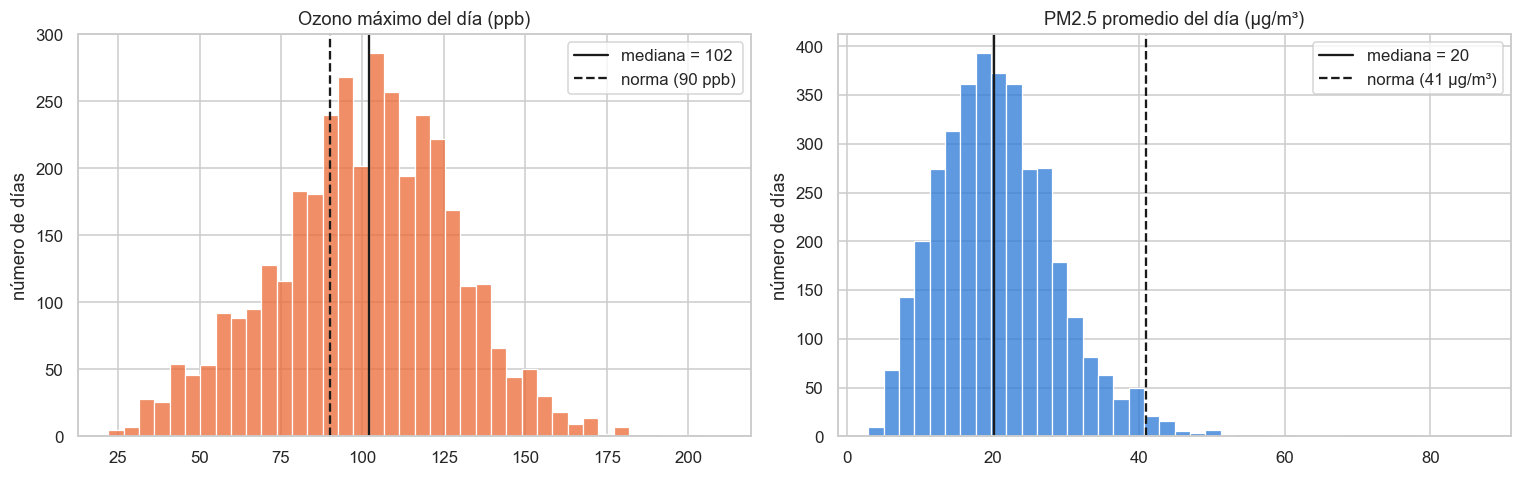

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col, etiqueta, color, limite, nombre_lim) in zip(axes, [
        ("o3_max1h", "Ozono máximo del día (ppb)", COLOR["O3"], NOM_O3_1H, "norma (90 ppb)"),
        ("pm25_prom", "PM2.5 promedio del día (µg/m³)", COLOR["PM2.5"], NOM_PM25_24H, "norma (41 µg/m³)")]):
    x = final[col].dropna()
    sns.histplot(x, bins=40, ax=ax, color=color)
    ax.axvline(x.median(), color="k", lw=1.5, label=f"mediana = {x.median():.0f}")
    ax.axvline(limite, color="k", ls="--", lw=1.5, label=nombre_lim)
    ax.set(title=etiqueta, xlabel="", ylabel="número de días")
    ax.legend()
fig.tight_layout()
guardar(fig, "distribucion_objetivos")
plt.show()

**Qué obtuvimos**

- **Ozono:** tiene forma de campana y es bastante simétrico. La mediana (102) queda a la derecha de la norma: lo normal es rebasarla.
- **PM2.5:** la mayoría de los días está entre 15 y 26, pero tiene una "cola" hacia la derecha: unos pocos días con valores muy altos.

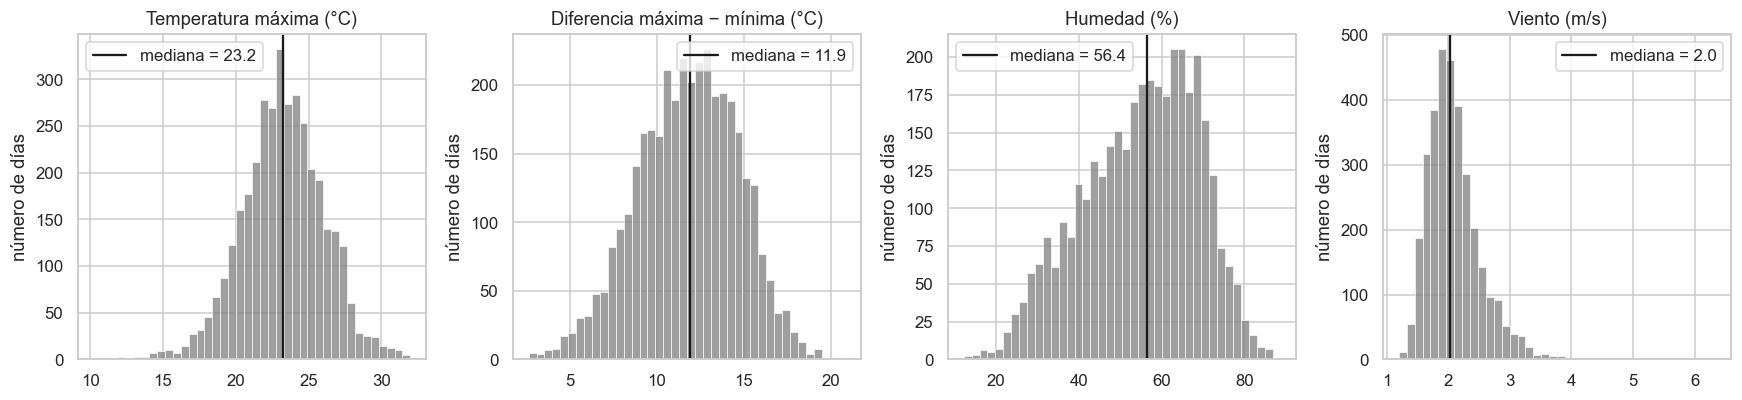

In [54]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (col, etiqueta) in zip(axes, [("tmp_max", "Temperatura máxima (°C)"), ("amplitud_termica", "Diferencia máxima − mínima (°C)"),
                                      ("rh_prom", "Humedad (%)"), ("wsp_prom", "Viento (m/s)")]):
    sns.histplot(final[col].dropna(), bins=40, ax=ax, color=COLOR["gris"])
    ax.axvline(final[col].median(), color="k", lw=1.5, label=f"mediana = {final[col].median():.1f}")
    ax.set(title=etiqueta, xlabel="", ylabel="número de días")
    ax.legend()
fig.tight_layout()
guardar(fig, "distribucion_entradas")
plt.show()

**Qué obtuvimos (variables de clima):** la temperatura máxima se concentra entre 21 y 25 °C; la humedad es la que más cambia de un día a otro (de 12% a 89%); el viento casi siempre está cerca de 2 m/s, con unos pocos días de mucho viento. Ninguna tiene valores imposibles.

### 7.5 Valores atípicos

**Qué buscamos:** los días que se salen de lo común (muy por arriba o por debajo del resto) y saber si son errores de medición o eventos reales. En el diagrama de caja, la caja contiene a la mitad de los días y los puntos sueltos son los días atípicos.

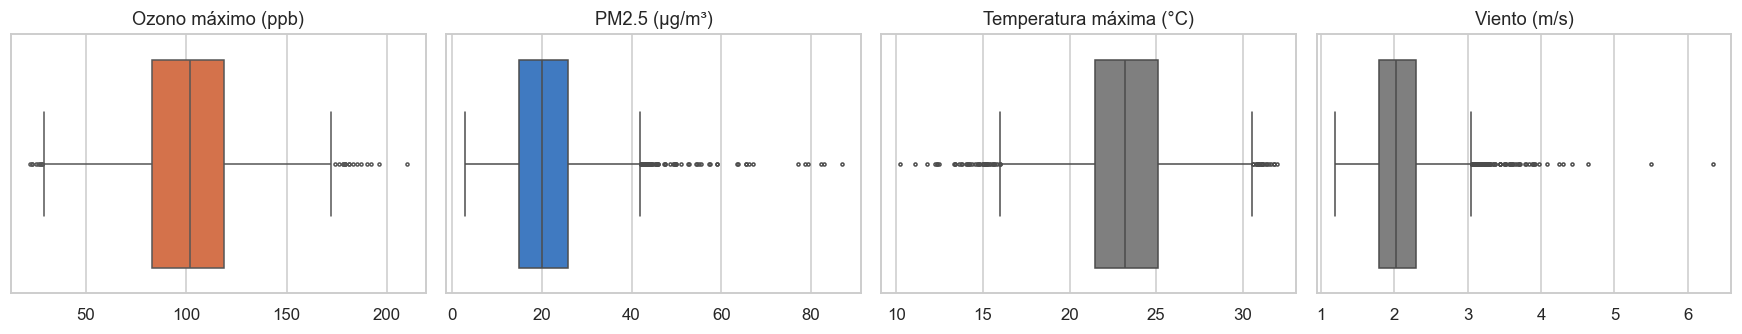

,días atípicos,porcentaje
o3_max1h,25,0.68
pm25_prom,66,1.81
no2_prom,72,1.97
co_prom,71,1.94
tmp_max,64,1.75
tmp_min,16,0.44
amplitud_termica,10,0.27
rh_prom,2,0.05
wsp_prom,111,3.04
wsp_madrugada,198,5.42


Los 10 días con más PM2.5


,pm25_prom,wsp_prom,rh_prom,festivo,dia
fecha,,,,,
2016-01-01,86.9,1.8,64.5,1,viernes
2015-12-25,82.8,1.4,58.6,1,viernes
2018-12-25,82.3,1.4,45.7,1,martes
2019-05-13,79.3,2.6,28.6,0,lunes
2015-01-01,78.7,1.9,60.6,1,jueves
2019-05-12,77.2,2.4,29.4,0,domingo
2019-05-16,67.1,2.1,55.8,0,jueves
2019-05-14,66.3,2.4,25.0,0,martes
2019-05-11,65.6,2.0,29.6,0,sábado


Los 10 días con más ozono


,o3_max1h,tmp_max,rh_prom,wsp_prom
fecha,,,,
2016-03-14,210.0,26.3,37.7,1.7
2016-05-04,196.0,27.1,45.5,2.3
2016-05-20,192.0,27.4,46.1,2.1
2017-05-20,190.0,29.6,40.0,2.2
2024-02-23,187.0,27.4,24.9,NaN
2017-05-23,185.0,29.7,44.5,2.2
2024-02-22,183.0,27.0,24.4,NaN
2016-03-13,181.0,26.1,35.6,1.6
2024-05-14,181.0,29.6,35.7,NaN


In [55]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (col, etiqueta, color) in zip(axes, [("o3_max1h", "Ozono máximo (ppb)", COLOR["O3"]), ("pm25_prom", "PM2.5 (µg/m³)", COLOR["PM2.5"]),
                                             ("tmp_max", "Temperatura máxima (°C)", COLOR["gris"]), ("wsp_prom", "Viento (m/s)", COLOR["gris"])]):
    sns.boxplot(x=final[col], ax=ax, color=color, fliersize=2)
    ax.set(title=etiqueta, xlabel="")
fig.tight_layout()
guardar(fig, "atipicos")
plt.show()

def atipicos(s):
    """Días fuera del rango habitual: más de 1.5 veces el ancho de la caja (del 25% al 75% de los datos)."""
    q1, q3 = s.quantile([0.25, 0.75])
    r = q3 - q1
    return int(((s < q1 - 1.5 * r) | (s > q3 + 1.5 * r)).sum())

tabla_at = pd.DataFrame({"días atípicos": {c: atipicos(final[c].dropna()) for c in PRINCIPALES}})
tabla_at["porcentaje"] = (tabla_at["días atípicos"] / len(final) * 100).round(2)
display(tabla_at)

NOMBRE_DIA = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
print("Los 10 días con más PM2.5")
display(final.nlargest(10, "pm25_prom").set_index("fecha")[["pm25_prom", "wsp_prom", "rh_prom", "festivo"]]
        .round(1).assign(dia=lambda t: [NOMBRE_DIA[d] for d in t.index.dayofweek]))
print("Los 10 días con más ozono")
display(final.nlargest(10, "o3_max1h").set_index("fecha")[["o3_max1h", "tmp_max", "rh_prom", "wsp_prom"]].round(1))

**Qué obtuvimos:** los valores atípicos son pocos (menos de 2% de los días en los contaminantes) y **no son errores, son eventos reales**:

- Los días con más PM2.5 son **Navidad y Año Nuevo** (25 de diciembre y 1 de enero), por la pirotecnia, y la semana del **11 al 16 de mayo de 2019**, cuando hubo incendios forestales y se declaró contingencia.
- Los días con más ozono caen entre **febrero y junio**, con temperaturas de 26 a 30 °C.

Por eso se conservan: son justo los días que interesa entender.

### 7.6 Comportamiento en el tiempo

**Qué buscamos:** saber si el aire ha mejorado en diez años (tendencia) y en qué meses, días de la semana y horas es peor (temporadas).

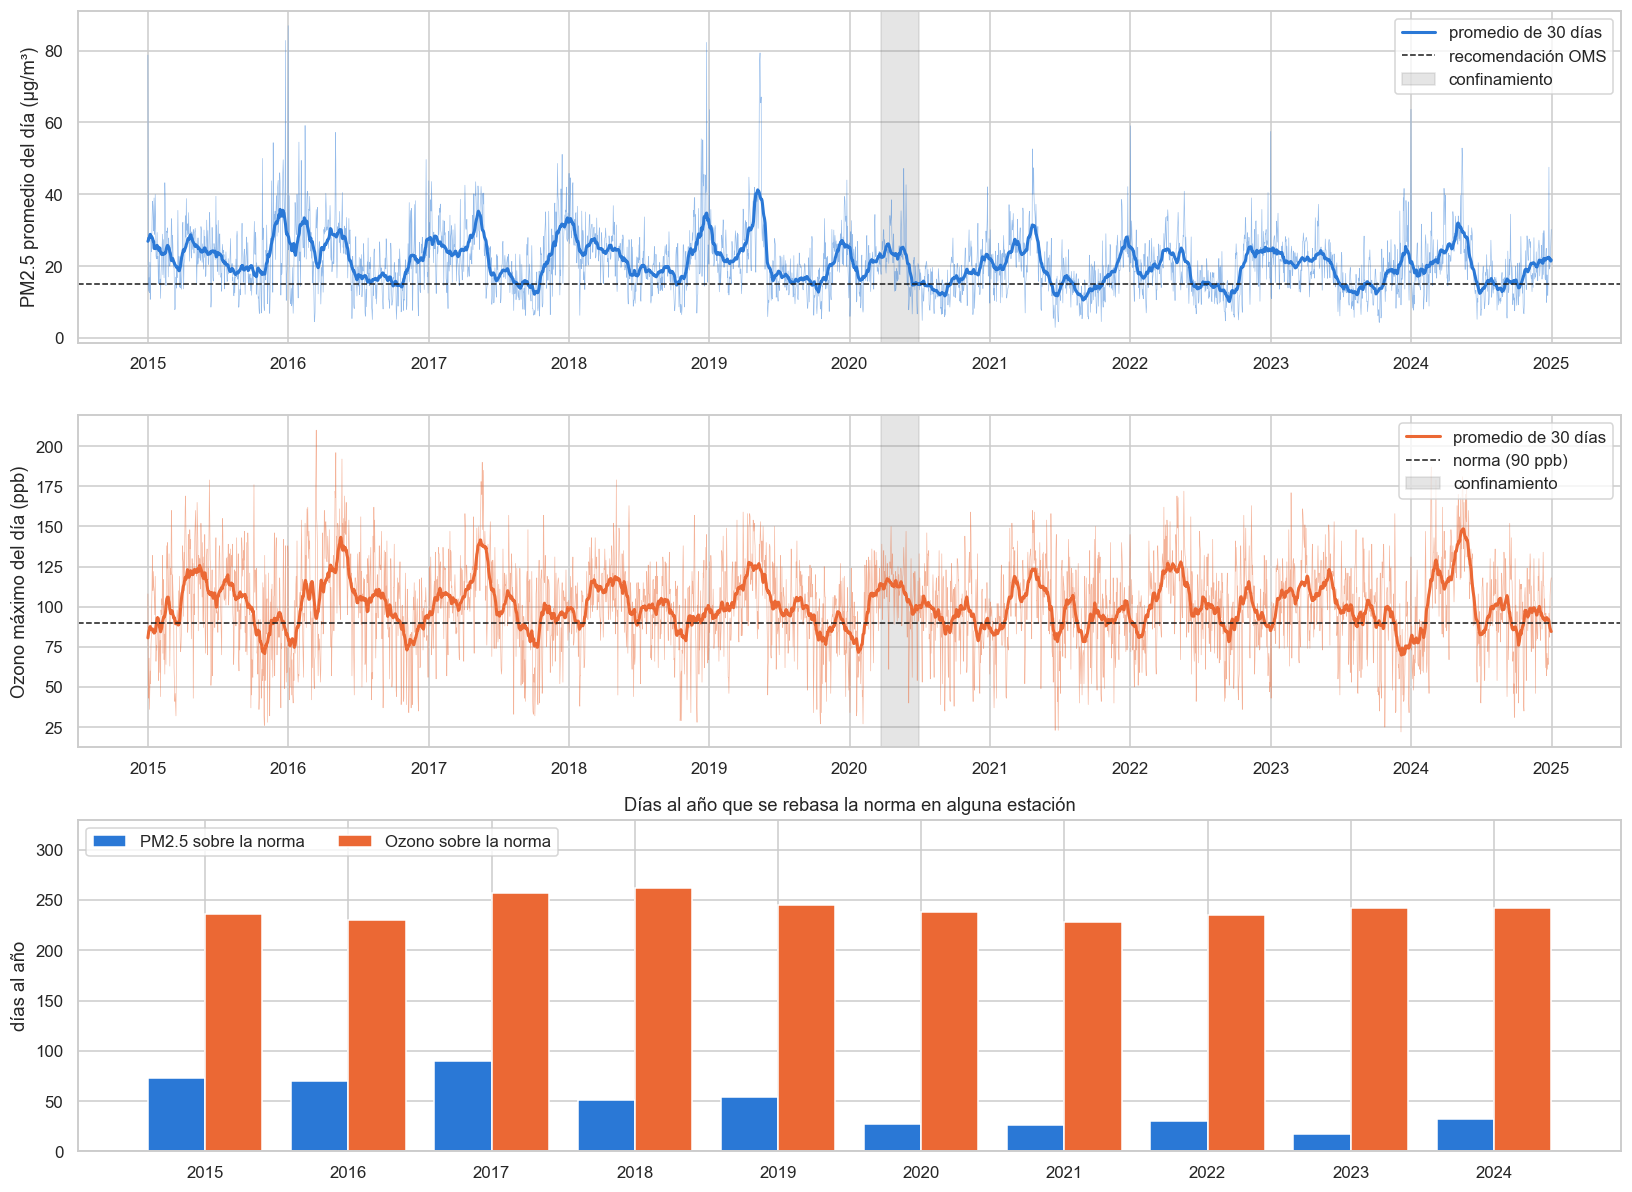

,PM2.5 promedio,ozono promedio,días PM2.5 sobre la norma,días ozono sobre la norma
año,,,,
2015,23.6,100.7,73.0,236.0
2016,22.0,102.2,70.0,230.0
2017,22.7,102.8,90.0,257.0
2018,22.8,99.8,51.0,262.0
2019,22.2,100.6,54.0,245.0
2020,18.6,97.8,27.0,238.0
2021,19.2,98.0,26.0,228.0
2022,19.2,100.8,30.0,235.0
2023,19.0,99.6,17.0,242.0


In [56]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=False)
for ax, (col, etiqueta, color, limite) in zip(axes[:2], [
        ("pm25_prom", "PM2.5 promedio del día (µg/m³)", COLOR["PM2.5"], OMS_PM25_24H),
        ("o3_max1h", "Ozono máximo del día (ppb)", COLOR["O3"], NOM_O3_1H)]):
    ax.plot(final.fecha, final[col], color=color, lw=0.4, alpha=0.5)
    ax.plot(final.fecha, final[col].rolling(30, center=True, min_periods=15).mean(), color=color, lw=2, label="promedio de 30 días")
    ax.axhline(limite, color="k", ls="--", lw=1, label="recomendación OMS" if col == "pm25_prom" else "norma (90 ppb)")
    ax.axvspan(pd.Timestamp("2020-03-23"), pd.Timestamp("2020-06-30"), color="grey", alpha=0.2, label="confinamiento")
    ax.set(ylabel=etiqueta)
    ax.legend(loc="upper right")

anual = final.groupby("año").agg(pm25=("pm25_prom", "mean"), o3=("o3_max1h", "mean"),
                                 dias_pm25=("excede_pm25", "sum"), dias_o3=("excede_o3", "sum"))
x = np.arange(len(anual))
axes[2].bar(x - 0.2, anual.dias_pm25, 0.4, color=COLOR["PM2.5"], label="PM2.5 sobre la norma")
axes[2].bar(x + 0.2, anual.dias_o3, 0.4, color=COLOR["O3"], label="Ozono sobre la norma")
axes[2].set_xticks(x, anual.index)
axes[2].set(ylabel="días al año", title="Días al año que se rebasa la norma en alguna estación", ylim=(0, 330))
axes[2].legend(loc="upper left", ncols=2)
fig.tight_layout()
guardar(fig, "serie_tiempo")
plt.show()
display(anual.round(1).rename(columns={"pm25": "PM2.5 promedio", "o3": "ozono promedio",
                                       "dias_pm25": "días PM2.5 sobre la norma", "dias_o3": "días ozono sobre la norma"}))

**Qué obtuvimos**

- **El PM2.5 sí mejoró:** a partir de 2020 el promedio bajó de 22-24 a 19-20 µg/m³ y los días sobre la norma pasaron de 50-90 al año a 17-32.
- **El ozono no ha mejorado en diez años:** todos los años se rebasa la norma entre 228 y 262 días.

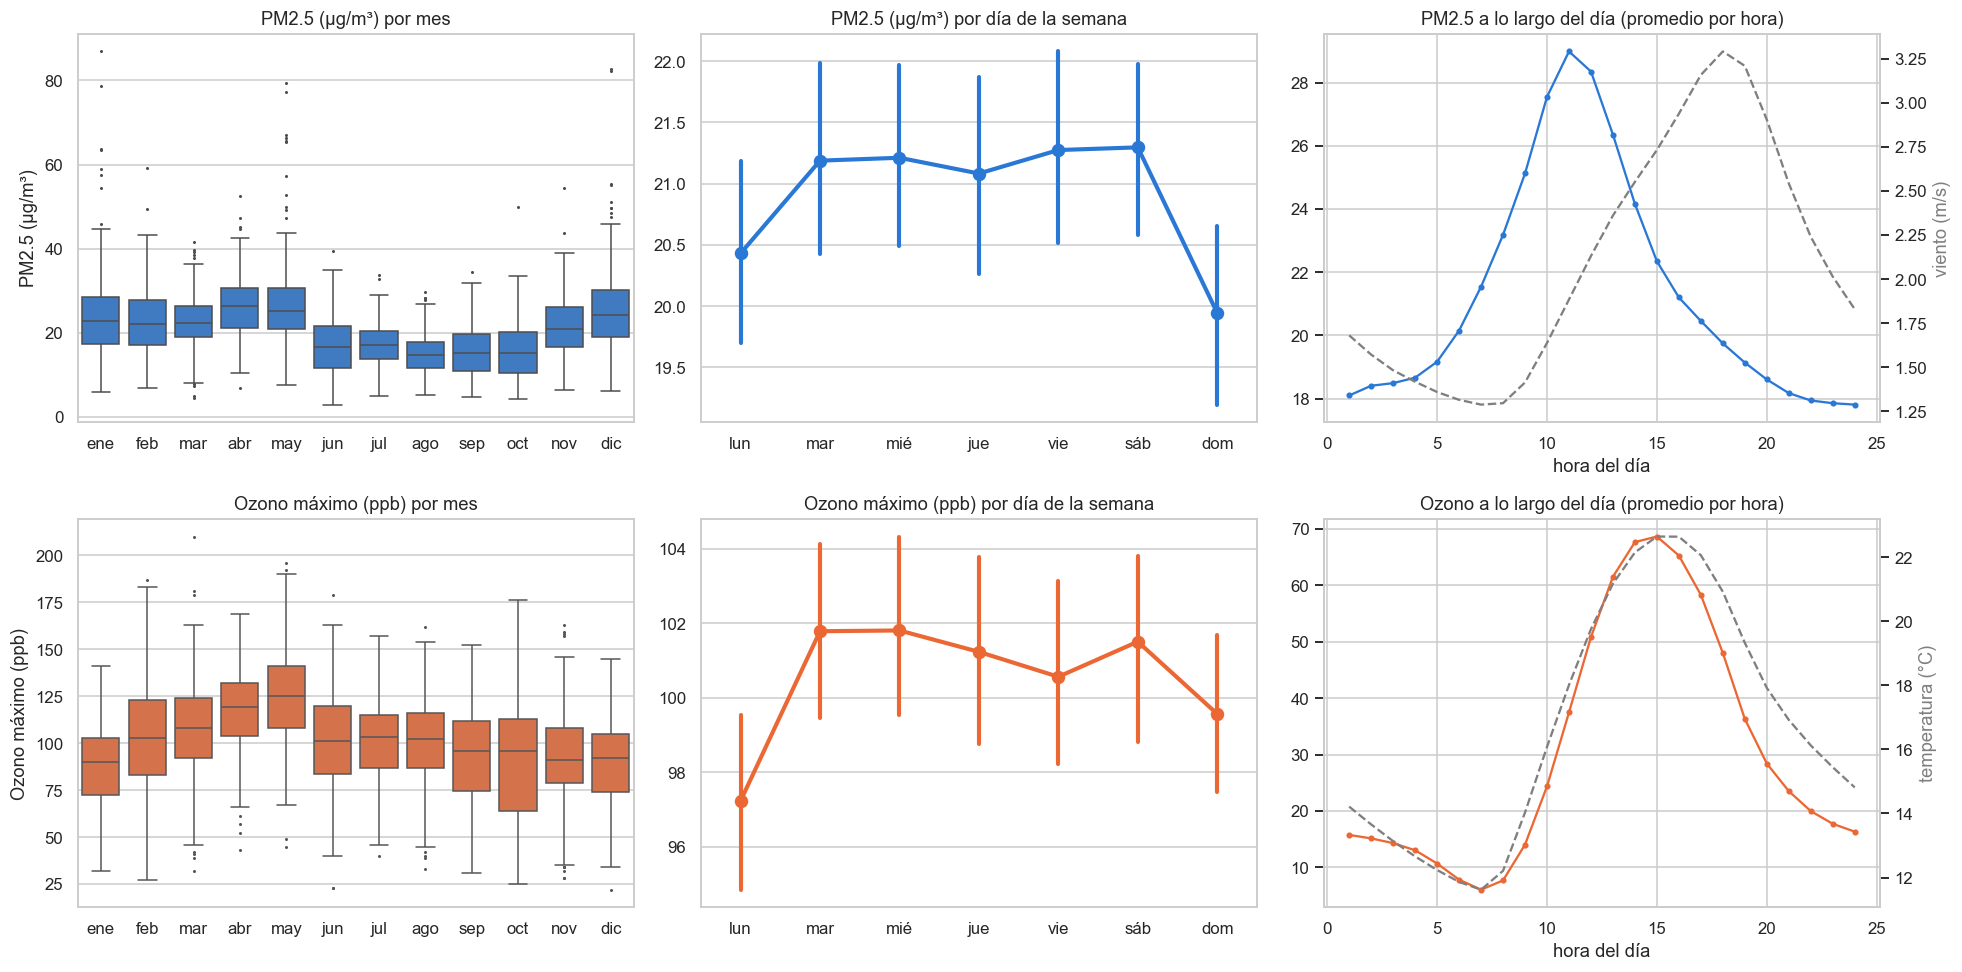

,PM2.5 promedio,ozono promedio,% días PM2.5 sobre la norma,% días ozono sobre la norma
ene,23.9,88.0,25.8,47.4
feb,22.7,102.6,18.7,68.6
mar,22.7,107.7,10.3,77.4
abr,26.2,117.7,22.0,88.3
may,27.0,125.0,22.9,91.0
jun,17.2,100.4,3.0,65.7
jul,17.1,100.9,1.0,68.7
ago,14.9,99.6,0.3,70.3
sep,15.6,93.0,2.0,60.0
oct,16.0,90.4,2.3,55.2


In [57]:
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for fila, (col, etiqueta, color) in enumerate([("pm25_prom", "PM2.5 (µg/m³)", COLOR["PM2.5"]),
                                               ("o3_max1h", "Ozono máximo (ppb)", COLOR["O3"])]):
    sns.boxplot(data=final, x="mes", y=col, ax=axes[fila, 0], color=color, fliersize=1)
    axes[fila, 0].set_xticks(range(12), MESES)
    axes[fila, 0].set(title=f"{etiqueta} por mes", xlabel="", ylabel=etiqueta)
    sns.pointplot(data=final, x="dia_semana", y=col, ax=axes[fila, 1], color=color, errorbar=("ci", 95))
    axes[fila, 1].set_xticks(range(7), DIAS)
    axes[fila, 1].set(title=f"{etiqueta} por día de la semana", xlabel="", ylabel="")
    param = "PM2.5" if fila == 0 else "O3"
    axes[fila, 2].plot(perfil_horario.index, perfil_horario[param], color=color, marker="o", ms=3)
    axes[fila, 2].set(title=f"{'PM2.5' if fila == 0 else 'Ozono'} a lo largo del día (promedio por hora)", xlabel="hora del día", ylabel="")
    eje2 = axes[fila, 2].twinx()
    eje2.plot(perfil_horario.index, perfil_horario["WSP" if fila == 0 else "TMP"], color=COLOR["gris"], ls="--")
    eje2.set_ylabel("viento (m/s)" if fila == 0 else "temperatura (°C)", color=COLOR["gris"])
    eje2.grid(False)
fig.tight_layout()
guardar(fig, "estacionalidad")
plt.show()

por_mes = final.groupby("mes")[["pm25_prom", "o3_max1h", "excede_pm25", "excede_o3"]].mean()
por_mes[["excede_pm25", "excede_o3"]] *= 100
por_mes.index = MESES
display(por_mes.round(1).rename(columns={"pm25_prom": "PM2.5 promedio", "o3_max1h": "ozono promedio",
                                         "excede_pm25": "% días PM2.5 sobre la norma", "excede_o3": "% días ozono sobre la norma"}))

**Qué obtuvimos**

- **Por mes:** el ozono es peor en **abril y mayo** (en mayo se rebasa la norma en 91% de los días), que son los meses más calurosos y secos antes de las lluvias. El PM2.5 es peor en **diciembre y enero** (frío, sin lluvia, fiestas) y baja mucho en la temporada de lluvias (junio a octubre).
- **Por día de la semana:** casi no cambia. Ni el domingo, con menos tráfico, baja de forma clara el ozono.
- **Por hora:** el ozono sube y baja junto con la temperatura (línea gris) y llega a su máximo a las **3 de la tarde**. El PM2.5 tiene su máximo a las **11 de la mañana**, después del tráfico matutino y antes de que el viento de la tarde lo disperse.

**¿Qué pasó cuando la ciudad se detuvo?** El confinamiento de 2020 (23 de marzo al 30 de junio) funciona como un experimento: hubo muchos menos autos. Comparamos esas mismas fechas contra el promedio de 2015 a 2019.

In [58]:
md_fecha = final.fecha.dt.strftime("%m%d")
mismas_fechas = (md_fecha >= "0323") & (md_fecha <= "0630")
cols = {"no2_prom": "NO2 (gas de los escapes)", "co_prom": "CO (gas de los escapes)", "pm25_prom": "PM2.5",
        "o3_max1h": "Ozono máximo", "tmp_max": "Temperatura máxima (°C)"}
antes = final[mismas_fechas & final.año.between(2015, 2019)][list(cols)].mean()
en2020 = final[mismas_fechas & (final.año == 2020)][list(cols)].mean()
tabla_conf = pd.DataFrame({"promedio 2015-2019": antes, "confinamiento 2020": en2020})
tabla_conf["cambio %"] = (tabla_conf.iloc[:, 1] / tabla_conf.iloc[:, 0] - 1) * 100
tabla_conf.index = list(cols.values())
display(tabla_conf.round(1))

dias_antes = final[mismas_fechas & final.año.between(2015, 2019)].excede_o3.mean() * 100
dias_2020 = final[mismas_fechas & (final.año == 2020)].excede_o3.mean() * 100
print(f"Días con ozono sobre la norma en esas fechas: {dias_antes:.0f}% en 2015-2019 y {dias_2020:.0f}% en 2020")

,promedio 2015-2019,confinamiento 2020,cambio %
NO2 (gas de los escapes),23.6,15.5,-34.4
CO (gas de los escapes),0.5,0.3,-50.4
PM2.5,25.0,21.8,-13.1
Ozono máximo,115.9,109.3,-5.7
Temperatura máxima (°C),24.8,25.9,4.4


Días con ozono sobre la norma en esas fechas: 82% en 2015-2019 y 86% en 2020


**Qué obtuvimos:** con la ciudad casi detenida, los gases que salen de los escapes bajaron mucho (NO2 −34%, CO −50%), el PM2.5 bajó 13%, pero **el ozono apenas bajó 6% y se siguió rebasando la norma en 86% de los días**. Quitar autos unos meses no bastó para bajar el ozono; el calor de esos meses pesó más.

### 7.7 Relación entre variables: el clima y la contaminación

**Qué buscamos:** cuáles variables de entrada se mueven junto con las variables objetivo, porque esas son las que servirán para explicar y anticipar la contaminación.

La **correlación** es un número entre −1 y 1 que dice qué tanto se mueven juntas dos variables: cerca de 1, cuando una sube la otra también; cerca de −1, cuando una sube la otra baja; cerca de 0, no tienen relación. (Usamos la correlación de Spearman, que funciona aunque la relación no sea una línea recta.)

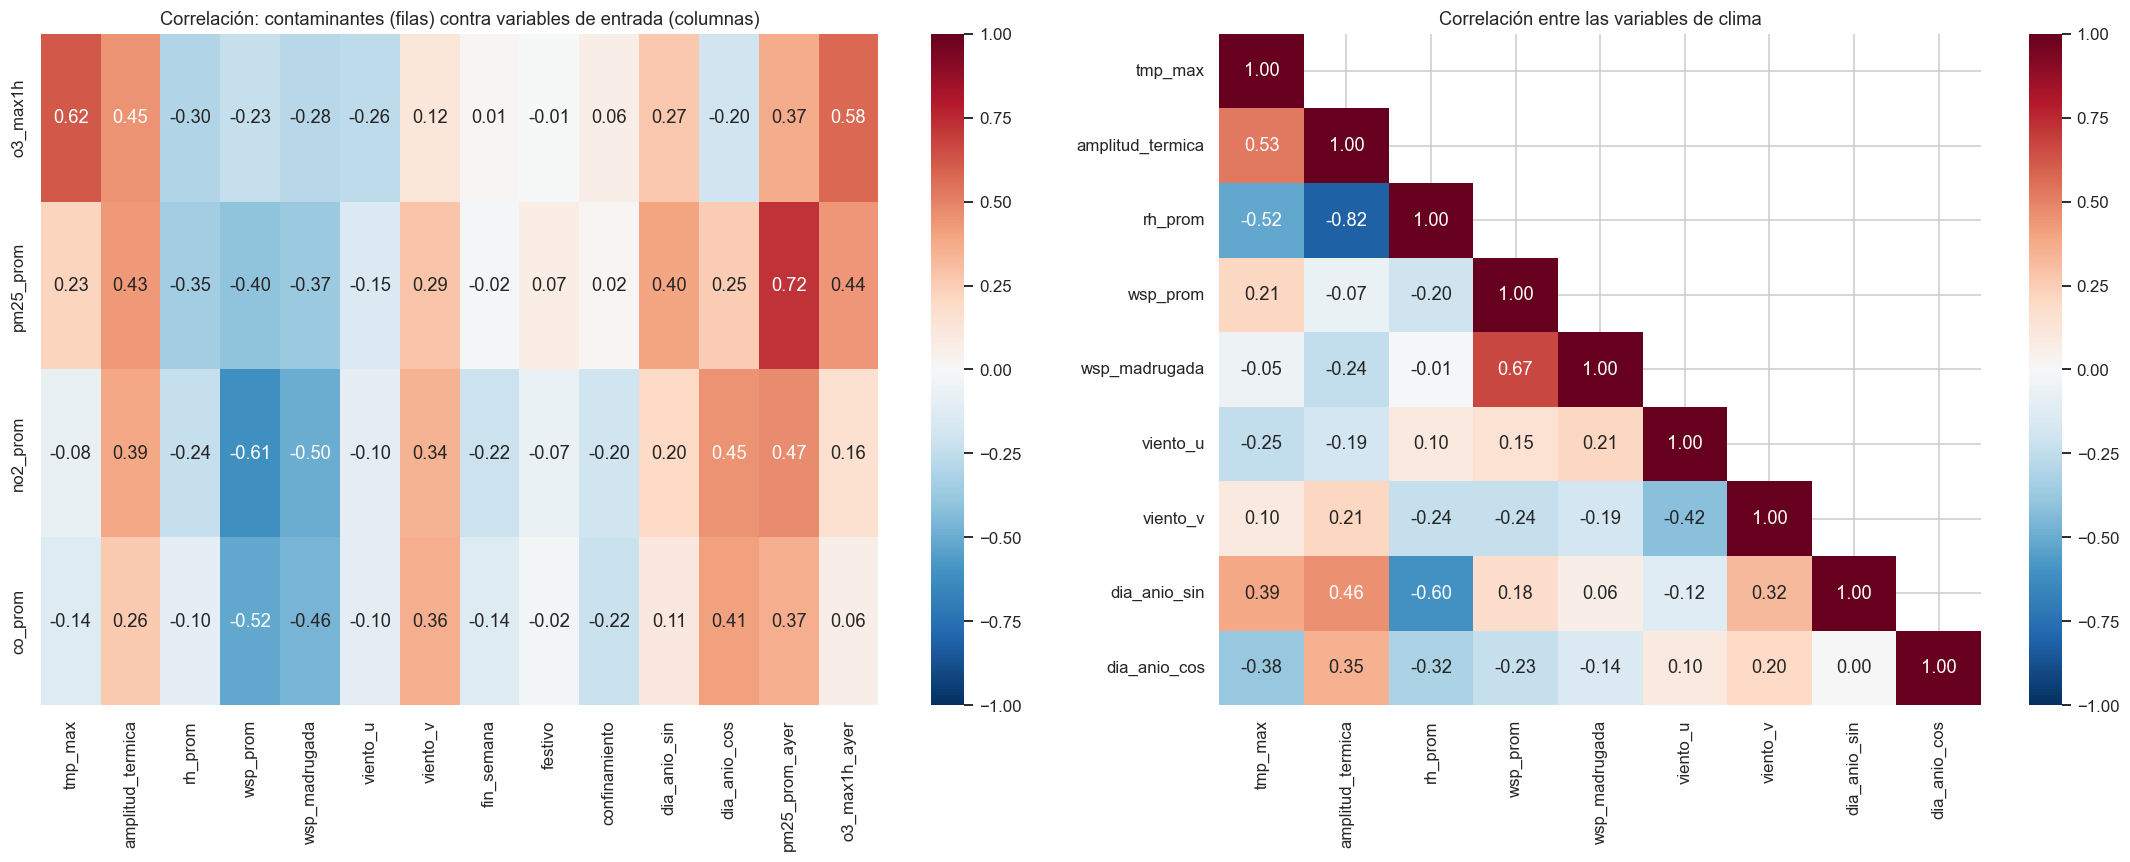

Correlación de cada variable de entrada con los dos objetivos (de mayor a menor)


,pm25_prom,o3_max1h
tmp_max,0.23,0.62
o3_max1h_ayer,0.44,0.58
amplitud_termica,0.43,0.45
pm25_prom_ayer,0.72,0.37
rh_prom,-0.35,-0.30
wsp_madrugada,-0.37,-0.28
dia_anio_sin,0.40,0.27
viento_u,-0.15,-0.26
wsp_prom,-0.40,-0.23
dia_anio_cos,0.25,-0.20


In [59]:
ENTRADAS = ["tmp_max", "amplitud_termica", "rh_prom", "wsp_prom", "wsp_madrugada", "viento_u", "viento_v",
            "fin_semana", "festivo", "confinamiento", "dia_anio_sin", "dia_anio_cos", "pm25_prom_ayer", "o3_max1h_ayer"]
OBJETIVOS = ["o3_max1h", "pm25_prom", "no2_prom", "co_prom"]

corr = final[OBJETIVOS + ENTRADAS].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(corr.loc[OBJETIVOS, ENTRADAS], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlación: contaminantes (filas) contra variables de entrada (columnas)")
met = ["tmp_max", "amplitud_termica", "rh_prom", "wsp_prom", "wsp_madrugada", "viento_u", "viento_v",
       "dia_anio_sin", "dia_anio_cos"]
sns.heatmap(corr.loc[met, met], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], mask=np.triu(np.ones((len(met),) * 2), 1).astype(bool))
axes[1].set_title("Correlación entre las variables de clima")
fig.tight_layout()
guardar(fig, "correlaciones")
plt.show()

print("Correlación de cada variable de entrada con los dos objetivos (de mayor a menor)")
display(corr.loc[ENTRADAS, ["pm25_prom", "o3_max1h"]].sort_values("o3_max1h", key=abs, ascending=False).round(2))

**Qué obtuvimos**

- **Ozono:** lo que más se relaciona es la **temperatura máxima (0.62)** y el **ozono de ayer (0.58)**.
- **PM2.5:** lo que más se relaciona es el **PM2.5 de ayer (0.72)**; después, el **viento (−0.40)**: a más viento, menos partículas.
- **Fin de semana, festivo y confinamiento** tienen correlación casi cero con el ozono y el PM2.5.
- Entre las variables de clima, la humedad y la amplitud térmica dicen casi lo mismo (−0.82), algo a cuidar en la siguiente etapa para no contar dos veces la misma información.

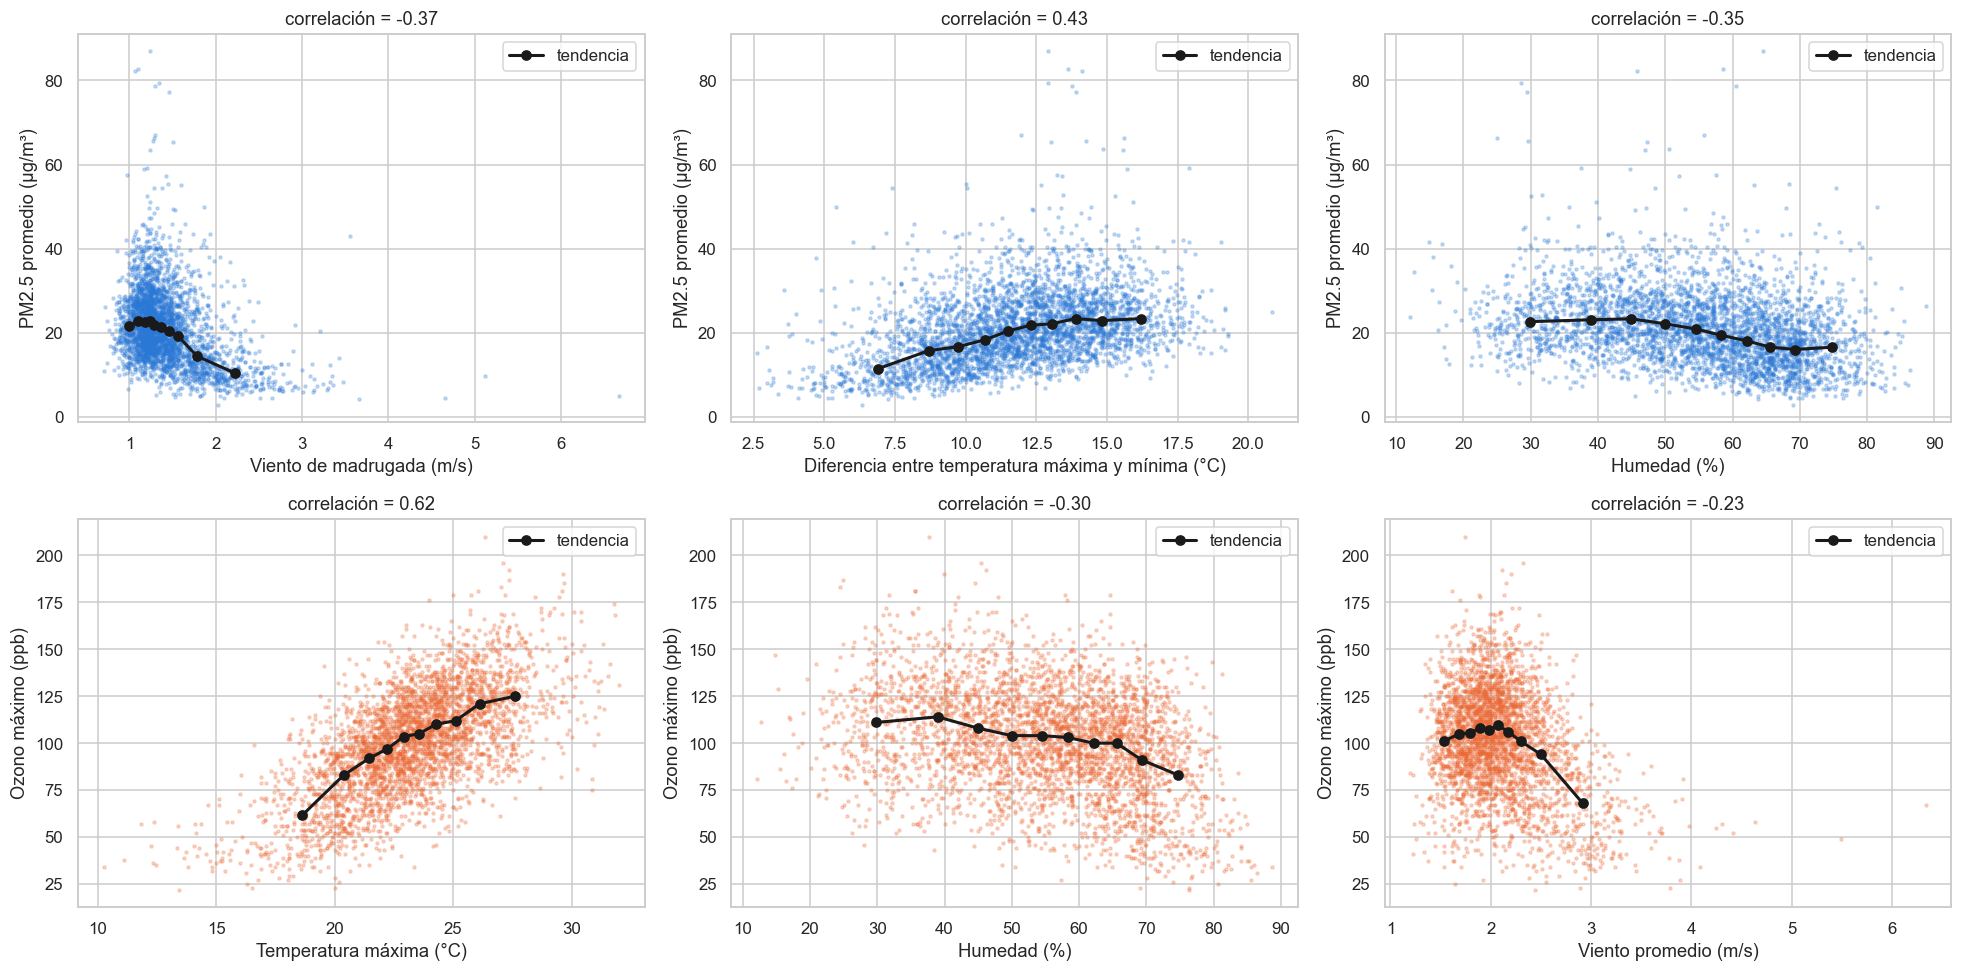

In [60]:
NOMBRE = {"pm25_prom": "PM2.5 promedio (µg/m³)", "o3_max1h": "Ozono máximo (ppb)"}
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
pares = [("wsp_madrugada", "pm25_prom", "Viento de madrugada (m/s)"),
         ("amplitud_termica", "pm25_prom", "Diferencia entre temperatura máxima y mínima (°C)"),
         ("rh_prom", "pm25_prom", "Humedad (%)"),
         ("tmp_max", "o3_max1h", "Temperatura máxima (°C)"),
         ("rh_prom", "o3_max1h", "Humedad (%)"),
         ("wsp_prom", "o3_max1h", "Viento promedio (m/s)")]
for ax, (x, y, etiqueta) in zip(axes.ravel(), pares):
    color = COLOR["PM2.5"] if y == "pm25_prom" else COLOR["O3"]
    d = final[[x, y]].dropna()
    ax.scatter(d[x], d[y], s=4, alpha=0.25, color=color)
    # tendencia: se parte x en 10 grupos del mismo tamaño y se marca el valor típico de cada grupo
    bins = pd.qcut(d[x], 10, duplicates="drop")
    tend = d.groupby(bins, observed=True).agg(xm=(x, "median"), ym=(y, "median"))
    ax.plot(tend.xm, tend.ym, color="k", marker="o", lw=2, label="tendencia")
    rho = stats.spearmanr(d[x], d[y])[0]
    ax.set(xlabel=etiqueta, ylabel=NOMBRE[y], title=f"correlación = {rho:.2f}")
    ax.legend(loc="upper right")
fig.tight_layout()
guardar(fig, "meteorologia_vs_contaminacion")
plt.show()

**Qué obtuvimos:** cada punto es un día y la línea negra marca la tendencia. El ozono sube de forma clara con la temperatura; el PM2.5 baja cuando hay viento en la madrugada y cuando el día es húmedo.

Para verlo de forma más directa, calculamos **en qué porcentaje de los días se rebasa la norma** según la temperatura, el viento y lo que pasó el día anterior.

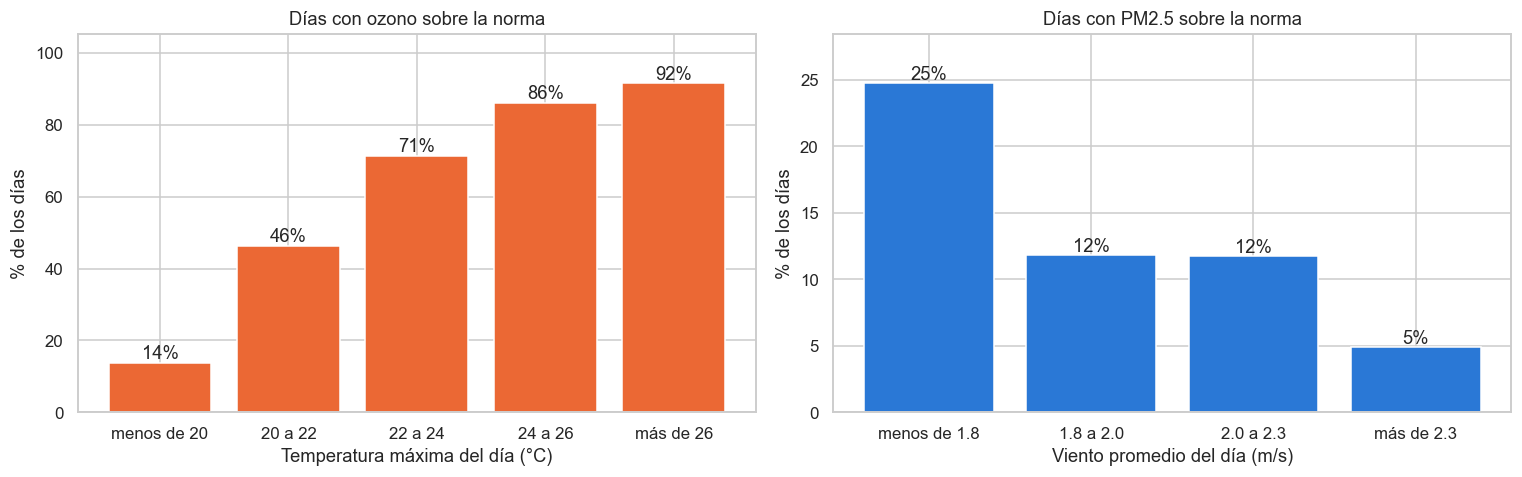

,días,% con ozono sobre la norma
temperatura máxima (°C),,
menos de 20,435,13.8
20 a 22,729,46.4
22 a 24,1067,71.3
24 a 26,840,86.1
más de 26,582,91.6


,días,% con PM2.5 sobre la norma
viento promedio (m/s),,
menos de 1.8,828,24.8
1.8 a 2.0,737,11.8
2.0 a 2.3,904,11.7
más de 2.3,818,4.9


Ozono: si ayer se rebasó la norma, hoy se rebasa en 79% de los casos; si ayer no, en 40%
PM2.5: si ayer se rebasó la norma, hoy se rebasa en 54% de los casos; si ayer no, en 7%


In [61]:
def pct_sobre_norma(variable, cortes, etiquetas, objetivo):
    grupo = pd.cut(final[variable], cortes, labels=etiquetas)
    return final.groupby(grupo, observed=True).agg(dias=(objetivo, "size"), pct=(objetivo, lambda s: s.mean() * 100))

por_temp = pct_sobre_norma("tmp_max", [0, 20, 22, 24, 26, 40], ["menos de 20", "20 a 22", "22 a 24", "24 a 26", "más de 26"], "excede_o3")
por_viento = pct_sobre_norma("wsp_prom", [0, 1.8, 2.0, 2.3, 10], ["menos de 1.8", "1.8 a 2.0", "2.0 a 2.3", "más de 2.3"], "excede_pm25")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (t, color, xlabel, titulo) in zip(axes, [
        (por_temp, COLOR["O3"], "Temperatura máxima del día (°C)", "Días con ozono sobre la norma"),
        (por_viento, COLOR["PM2.5"], "Viento promedio del día (m/s)", "Días con PM2.5 sobre la norma")]):
    barras = ax.bar(t.index.astype(str), t.pct, color=color)
    ax.bar_label(barras, fmt="%.0f%%")
    ax.set(xlabel=xlabel, ylabel="% de los días", title=titulo, ylim=(0, t.pct.max() * 1.15))
fig.tight_layout()
guardar(fig, "riesgo_por_clima")
plt.show()

display(por_temp.round(1).rename(columns={"dias": "días", "pct": "% con ozono sobre la norma"}).rename_axis("temperatura máxima (°C)"))
display(por_viento.round(1).rename(columns={"dias": "días", "pct": "% con PM2.5 sobre la norma"}).rename_axis("viento promedio (m/s)"))

ayer_o3 = final.groupby(final.o3_max1h_ayer > NOM_O3_1H).excede_o3.mean() * 100
ayer_pm = final.groupby(final.excede_pm25.shift(1) == 1).excede_pm25.mean() * 100
print(f"Ozono: si ayer se rebasó la norma, hoy se rebasa en {ayer_o3[True]:.0f}% de los casos; si ayer no, en {ayer_o3[False]:.0f}%")
print(f"PM2.5: si ayer se rebasó la norma, hoy se rebasa en {ayer_pm[True]:.0f}% de los casos; si ayer no, en {ayer_pm[False]:.0f}%")

**Qué obtuvimos**

- **Temperatura y ozono:** con menos de 20 °C se rebasa la norma en 14% de los días; con más de 26 °C, en **92%**.
- **Viento y PM2.5:** con poco viento se rebasa la norma en 25% de los días; con viento fuerte, en 5%.
- **Los días malos vienen en racha:** si ayer se rebasó la norma de ozono, hoy se rebasa en 79% de los casos (contra 40% si ayer no). En PM2.5 es 54% contra 7%.

### 7.8 ¿El satélite coincide con las estaciones?

**Qué buscamos:** saber si podemos confiar en el satélite. El satélite cubre toda la zona, pero es una estimación. Antes de confiar en él lo comparamos con lo que midieron las estaciones en 2020. Si coincidieran, los puntos caerían sobre la línea punteada.

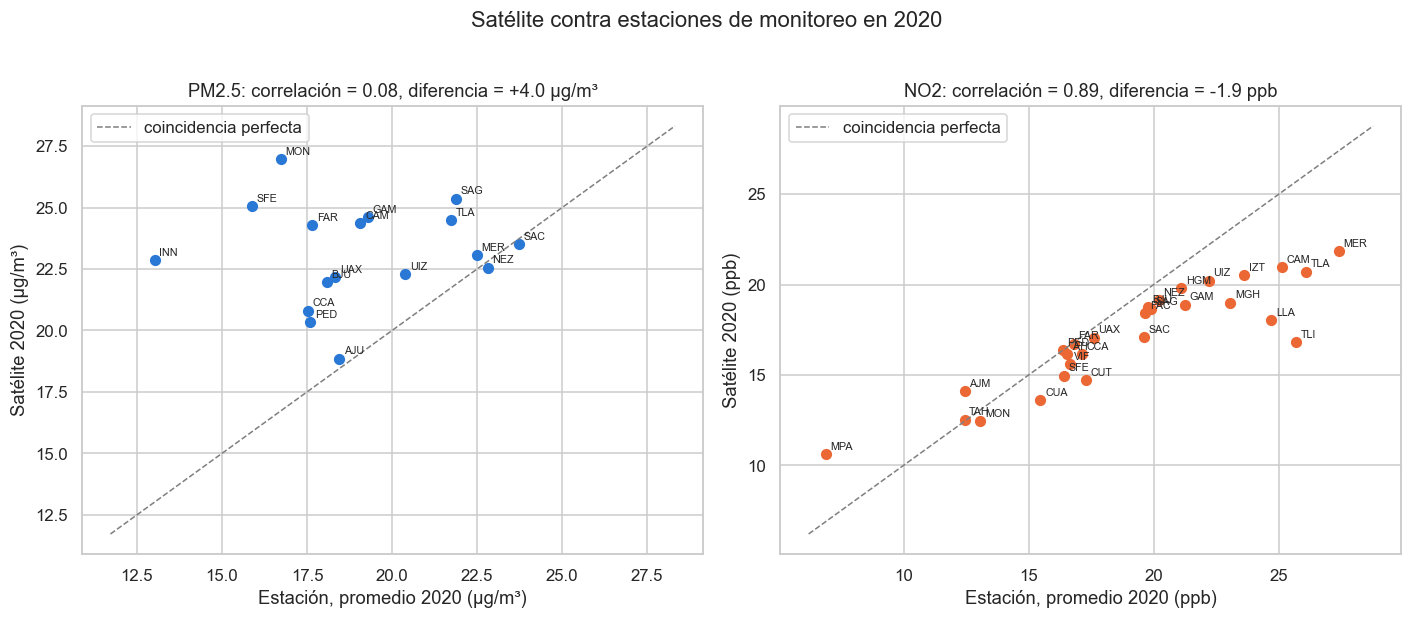

,contaminante,estaciones comparadas,correlación,promedio estaciones,promedio satélite,diferencia (satélite − estación)
0,PM2.5,17,0.08,19.10,23.150000,4.05
1,NO2,28,0.89,19.08,17.139999,-1.95


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
validacion = []
for ax, (medido, sat, etiqueta, unidad) in zip(axes, [("pm25_prom_2020", "pm25_sat", "PM2.5", "µg/m³"),
                                                    ("no2_prom_2020", "no2_sat", "NO2", "ppb")]):
    d = est[[medido, sat, "id_station"]].dropna()
    rho = stats.spearmanr(d[medido], d[sat])[0]
    diferencia = (d[sat] - d[medido]).mean()
    validacion.append({"contaminante": etiqueta, "estaciones comparadas": len(d), "correlación": rho,
                       "promedio estaciones": d[medido].mean(), "promedio satélite": d[sat].mean(),
                       "diferencia (satélite − estación)": diferencia})
    ax.scatter(d[medido], d[sat], color=COLOR["PM2.5"] if etiqueta == "PM2.5" else COLOR["O3"], s=40)
    for _, f in d.iterrows():
        ax.annotate(f.id_station, (f[medido], f[sat]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    lim = [min(d[medido].min(), d[sat].min()) * 0.9, max(d[medido].max(), d[sat].max()) * 1.05]
    ax.plot(lim, lim, color=COLOR["gris"], ls="--", lw=1, label="coincidencia perfecta")
    ax.set(xlabel=f"Estación, promedio 2020 ({unidad})", ylabel=f"Satélite 2020 ({unidad})",
           title=f"{etiqueta}: correlación = {rho:.2f}, diferencia = {diferencia:+.1f} {unidad}")
    ax.legend()
fig.suptitle("Satélite contra estaciones de monitoreo en 2020", y=1.02)
fig.tight_layout()
guardar(fig, "validacion_satelite")
plt.show()
display(pd.DataFrame(validacion).round(2))

**Qué obtuvimos**

- **NO2: el satélite sí coincide** con las estaciones (correlación de 0.89). Se puede usar donde no hay estación.
- **PM2.5: el satélite no coincide** (correlación de 0.08) y en promedio marca 4 µg/m³ de más. Sirve para dar una idea general de la zona, pero no para comparar una colonia con otra. Para PM2.5 nos quedamos con las estaciones.

### 7.9 ¿Quién respira el aire más contaminado?

**Qué buscamos:** cuánta gente, y de qué grupos, vive donde más se rebasa la norma. Con el dataset por localidad contamos cuánta gente vive cerca (5 km o menos) de las estaciones donde más se rebasa la norma de ozono.

In [63]:
def media_pond(x, w):
    """Promedio que le da más peso a las localidades con más habitantes."""
    ok = x.notna() & w.notna()
    return np.average(x[ok], weights=w[ok]) if ok.any() else np.nan

def resumen_exposicion(g):
    w = g.POBTOT
    cerca = g.o3_dias_sobre_nom.notna()
    return pd.Series({
        "localidades": len(g),
        "población": w.sum(),
        f"% de la población a {RADIO_KM} km o menos de una estación de ozono": w[cerca].sum() / w.sum() * 100,
        "días al año con ozono sobre la norma (población con estación cerca)": media_pond(g.o3_dias_sobre_nom, w),
        "PM2.5 por satélite (µg/m³)": media_pond(g.pm25_sat, w),
        "NO2 por satélite (ppb)": media_pond(g.no2_sat, w),
    })

expo = loc.groupby("NOM_ENT")[["POBTOT", "o3_dias_sobre_nom", "pm25_sat", "no2_sat"]].apply(resumen_exposicion)
display(expo.round(1).T)

# Población que vive cerca de una estación con muchos días de ozono sobre la norma
cerca = loc[loc.o3_dias_sobre_nom.notna()]
umbral = 120
mucho = cerca[cerca.o3_dias_sobre_nom > umbral]
vuln = ["POBTOT", "POB0_14", "POB65_MAS", "PSINDER"]
tabla_vuln = pd.DataFrame({f"cerca de una estación con más de {umbral} días al año sobre la norma": mucho[vuln].sum(),
                           f"total con estación a {RADIO_KM} km o menos": cerca[vuln].sum()})
tabla_vuln["%"] = tabla_vuln.iloc[:, 0] / tabla_vuln.iloc[:, 1] * 100
tabla_vuln.index = ["Población total", "Niños de 0 a 14", "Adultos de 65 o más", "Sin servicio médico"]
display(tabla_vuln.round(1))

NOM_ENT,Ciudad de México,México
localidades,494.0,4591.0
población,9209260.0,16985642.0
% de la población a 5 km o menos de una estación de ozono,97.7,40.5
días al año con ozono sobre la norma (población con estación cerca),125.7,65.3
PM2.5 por satélite (µg/m³),23.0,23.5
NO2 por satélite (ppb),18.3,13.5


,cerca de una estación con más de 120 días al año sobre la norma,total con estación a 5 km o menos,%
Población total,4454495,15872496,28.1
Niños de 0 a 14,733012,3075306,23.8
Adultos de 65 o más,534121,1624649,32.9
Sin servicio médico,1148590,4681366,24.5


**Qué obtuvimos**

- **4.45 millones de personas** viven cerca de una estación que rebasa la norma de ozono **más de 120 días al año** (uno de cada tres días). Entre ellas hay **733 mil niños** y **534 mil adultos mayores**.
- Los adultos mayores están más expuestos que el promedio: 33% de ellos vive en esas zonas, contra 28% de la población total.
- En la CDMX casi toda la población (98%) tiene una estación cerca; en el Estado de México solo 40%. De **6 de cada 10 habitantes del Estado de México no sabemos con precisión qué aire respiran**.

### 7.10 Resumen del EDA

| Paso del EDA | Qué obtuvimos |
|---|---|
| Conocer el dataset | 3,653 días (2015-2024) y 25 columnas, todas numéricas salvo la fecha |
| Calidad de los datos | Sin días repetidos ni días sin registro. Solo falta el viento de 2024 (10%), que quitamos por no ser confiable |
| Estadística descriptiva | El ozono típico (100 ppb) está arriba de la norma (90): se rebasa en 66% de los días. El PM2.5, en 13% |
| Distribuciones | El ozono tiene forma de campana; el PM2.5 tiene unos pocos días con valores muy altos |
| Valores atípicos | Son menos de 2% de los días y son eventos reales (pirotecnia e incendios), no errores. Se conservan |
| Comportamiento en el tiempo | El PM2.5 bajó desde 2020; el ozono no. El ozono es peor en abril-mayo y a las 3 de la tarde |
| Relación entre variables | Ozono: temperatura (0.62) y ozono de ayer (0.58). PM2.5: PM2.5 de ayer (0.72) y viento (−0.40) |
| Dataset por localidad | El satélite sirve para NO2 pero no para PM2.5. 4.45 millones de personas viven donde más ozono hay |

**Conclusión del EDA:** los datos están limpios y completos, y las variables de entrada que propusimos (sobre todo temperatura, viento y la contaminación del día anterior) sí se relacionan con las variables objetivo.

## 8. Hallazgos y qué podemos hacer con ellos

### Lo que encontramos

1. **El problema de fondo es el ozono, y no ha mejorado.** Se rebasa la norma en 2 de cada 3 días (66%), todos los años, de 2015 a 2024. El PM2.5 sí bajó a partir de 2020.
2. **El calor es la mejor pista del ozono.** Con menos de 20 °C se rebasa la norma en 14% de los días; con más de 26 °C, en 92%. Por eso abril y mayo son los peores meses y las 3 de la tarde la peor hora.
3. **El viento limpia las partículas.** Con poco viento el PM2.5 rebasa la norma cinco veces más seguido que con viento fuerte. Sus peores días son Navidad, Año Nuevo (pirotecnia) y los incendios de mayo de 2019.
4. **Los días malos vienen en racha.** Si ayer se rebasó la norma de ozono, hoy hay 79% de probabilidad de que se repita.
5. **Sacar autos de circulación no basta para bajar el ozono.** En el confinamiento de 2020 los gases de los escapes bajaron entre 34% y 50%, pero el ozono solo 6%. Tampoco baja en fin de semana. Fue lo que más nos sorprendió.
6. **El ozono pega más en el sur y poniente de la ciudad** (Pedregal, Ciudad Universitaria, Coyoacán, Ajusco: más de 150 días al año), no en el norte industrial. Ahí viven 4.45 millones de personas, incluidos 733 mil niños y 534 mil adultos mayores.
7. **No todos los datos son igual de confiables.** El satélite sirve para NO2 pero no para PM2.5, y el viento de 2024 viene mal en la fuente oficial. Si no se revisa, se llega a conclusiones equivocadas.

### Límites de este avance

- Lo que vimos son **relaciones**, no pruebas de causa: que el ozono suba con el calor no significa que el calor sea lo único que lo provoca.
- Las estaciones solo cubren al 61% de la población; del resto no tenemos mediciones directas.
- El satélite es solo de 2020 y falta el viento de 2024.